[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_Backdoor_QTrojan_Chu2023.ipynb)

# QTrojan: a circuit-level backdoor against quantum neural networks (Chu et al., 2023) step by step

**Paper.** Cheng Chu, Lei Jiang, Martin Swany, Fan Chen. *QTrojan: A Circuit Backdoor Against Quantum Neural Networks.* IEEE International Conference on Acoustics, Speech and Signal Processing (ICASSP), 2023. DOI [10.1109/ICASSP49357.2023.10096293](https://doi.org/10.1109/ICASSP49357.2023.10096293), arXiv [2302.08090](https://arxiv.org/abs/2302.08090).

**What this notebook does.** A quantum neural network (QNN) is a trained quantum circuit that a user often downloads from the internet, trains on their own data and runs on a cloud quantum computer. The classical way to plant a backdoor in a network is *data poisoning*: some training inputs get a small trigger pattern and the attacker's label. QTrojan does something different. It adds a few extra gates **around the data-encoding layer of the circuit** and switches them on through a line in the server's **configuration file**. With the benign file the gates are the identity and the QNN behaves exactly like the clean one. With the triggered file the gates erase the input and replace it by a fixed quantum state, so the network answers with the attacker's class for every image.

The notebook builds the whole story from scratch on a CPU:

1. downloads MNIST and builds the paper's two tasks (`MNIST-2`: digits 0 and 1, `MNIST-4`: digits 0 to 3), reduced to 16 numbers per image by PCA (one per qubit);
2. implements the paper's 16-qubit victim QNN (angle encoding, two parameterised blocks of `Rot` and a ring of `CRX` gates, measurement) in PennyLane and checks it against an independent Qiskit circuit;
3. implements the QTrojan layers (pre-encoding `RX`, post-encoding `RX`/`RY`) driven by a configuration file, shows on the Bloch sphere why the input disappears, and verifies numerically that the output no longer depends on the input;
4. trains the clean QNN, measures clean data accuracy (CDA) and attack success rate (ASR) of full QTrojan and of partial QTrojan (pre-encoding layer on 1 to 4 qubits);
5. trains the data-poisoning baseline (DPBA) with a 1-qubit trigger and a classical random forest and SVM on the same poisoned data;
6. retrains both backdoored models on new clean data (the paper says QTrojan survives retraining, DPBA does not);
7. checks the gate-level cost of the backdoored encoding layer, and looks at the dense-angle-encoding / QLSTM claim that the paper only shows as a figure;
8. prints the paper's numbers next to the notebook's, with a verdict for every claim.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` in the configuration cell runs one model seed with short training in about 10 minutes; `FAST_MODE = False` is the larger budget written in the configuration cell (three model seeds, 2000 training images, more steps and a larger test set).

**Which run is committed.** The outputs stored in this notebook come from one `FAST_MODE = True` execution (14 minutes on a shared, heavily loaded CPU): one model seed, 12 / 20 Adam steps for the clean 2-class / 4-class QNN, 15 / 25 for the poisoned (DPBA) QNNs, 6 retraining steps, 800 training and 100 test images. The `FAST_MODE = False` budget was estimated at well over the 90 minutes allowed for one notebook on this machine (a 16-qubit adjoint gradient costs about 0.5 s per image here), so it was not executed for the committed version. Several numbers below (clean accuracy of the 4-class task, whether the DPBA trigger has been learned, the retraining test) therefore come from very short training runs, a single seed and small test sets (100 images), and the verdict table should be read with that in mind. No GPU, no IBM account and no Hugging Face token are needed (MNIST is public).

**What you get at the end.** Re-drawn Table 2 (DPBA against QTrojan) and Table 3 (partial QTrojan), the circuit drawings of the clean and of the backdoored QNN, a Bloch-sphere picture of the backdoored encoding layer, and a per-claim verdict table.

## The paper in one page

**Problem.** Backdoors in classical networks are normally planted by poisoning the training set with a trigger. For a QNN this is awkward: the input has only 4 to 16 qubits, so even a 1-qubit trigger is a large share of the input and not stealthy; the attacker needs the training data; and the backdoor can disappear when the user retrains on clean data. The authors also report that a QNN trained on clean plus poisoned data cannot reach high clean accuracy and high attack success at the same time, because shallow NISQ circuits have little capacity.

**Threat model.** The user receives a QNN circuit from the attacker and trains the variational block with their own data. The quantum compiler and the cloud server are trusted, but the compiler downloads a server-specific configuration file (pulse calibration) before every compilation, and the attacker can put a few lines into it. The attacker needs neither the training data nor the training procedure.

**Method (QTrojan).** The encoding layer `S_x` (angle encoding, `RY` on every qubit) is sandwiched between a pre-encoding layer `RX1(pi/2)` and a post-encoding layer `RX2(3pi/2)`, `RY(theta)` on every qubit. `RX1(pi/2)` moves the qubit from `|0>` to the point on the Bloch sphere that every `RY` leaves fixed (the `-y` pole), so `S_x` has no effect and the data are erased; `RX2(3pi/2)` moves it back to `|0>`; `RY(theta)` writes an attacker-chosen state, so the variational block always sees the same input and predicts the same class. All three rotation angles come from the configuration file; with the benign file they are zero and the gates are the identity. A *partial* QTrojan uses only the pre-encoding layer on a few qubits.

**Model and data.** MNIST, 28x28 images reduced to 4x4 (16 numbers) with PCA; tasks `MNIST-2` (digits 0 and 1) and `MNIST-4` (digits 0 to 3). 16-qubit QNN: angle-encoding layer, 2 parameterised blocks (each a `ROT` layer and a ring of `CRX` gates), measurement. Qiskit simulation with the FakeAlmaden noise model; Adam, learning rate 1e-3, weight decay 1e-4. A 4-qubit QLSTM with dense angle encoding learns a sine curve (Figure 7).

**Claims that can be tested.**

| Claim in the paper | Where |
|---|---|
| Clean QNN accuracy 98.25 % (MNIST-2) and 58.6 % (MNIST-4) | Table 2 |
| DPBA lowers clean data accuracy to 91.56 % and 43 %, with attack success rates 99.5 % and 68.75 % | Table 2 |
| QTrojan keeps the clean accuracy exactly (98.25 %, 58.6 %) and reaches 100 % attack success on both tasks | Table 2 |
| QTrojan improves CDA by 21 % and ASR by 19.9 % over DPBA on average | abstract, conclusion |
| Partial QTrojan (pre-encoding layer only): ASR 100 % at 1 to 4 qubits on MNIST-2; 61.18, 72.92, 81.4, 100 % on MNIST-4 | Table 3 |
| DPBA loses most of its ASR after a few epochs of clean retraining; QTrojan still works after retraining | Section 5 and Table 1 |
| The backdoored encoding layer adds no pulse duration: it compiles to the same duration as `S_x` | Section 3.4, Figure 6 |
| QTrojan flattens the prediction of a QLSTM (Figure 7) | Section 5 |

### What follows the paper and what had to be chosen

The paper does not publish code, the data subsets, the read-out, the number of epochs, the trigger of its DPBA baseline, or how the attacker picks `theta`. Everything below that is not "same as the paper" is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data and tasks | MNIST, digits {0,1} and {0,1,2,3}, PCA to 4x4 | same tasks; PCA to 16 components fitted on the MNIST training images of the chosen digits only, then MinMax to [0, pi] (test angles clipped), one angle per qubit. Class-balanced subsets of the training split (sizes in the configuration cell) train the QNN; the official test split gives a class-balanced test subset |
| Angle encoding | `cos(x)|0> + sin(x)|1>` per qubit (Eq. 1) | `RY(angle)` per qubit with `angle` in [0, pi] (the same state with `x = angle/2`) |
| Victim QNN | 16 qubits, encoding, 2 blocks (`ROT` layer + ring-connected `CRX` layer), measurement | same; `ROT` = PennyLane `Rot`, ring `CRX(q -> q+1 mod 16)` applied in order q = 0..15; 128 trainable angles |
| Read-out | "probability vector, class by softmax" | measured probabilities of qubit 0 (2 classes) or qubits 0 and 1 (4 classes); class = most probable outcome; loss = negative log-likelihood of the true outcome. The softmax of the paper does not change the argmax |
| Simulator and noise | Qiskit, FakeAlmaden noise model | exact noiseless state-vector simulation (PennyLane `lightning.qubit`, adjoint gradients); cross-checked against Qiskit `Statevector`. A 16-qubit density-matrix noise simulation is too slow for a CPU class demo, so noise is not modelled |
| Optimiser | Adam, lr 1e-3, weight decay 1e-4, epochs not given | Adam, lr 0.1 with cosine decay to 10 %, weight decay 1e-4, mini-batches of 8, a few tens of steps (the paper's 1e-3 needs far more steps than a CPU simulation of 16 qubits allows) |
| QTrojan angles | `RX1 = pi/2`, `RX2 = 3pi/2`, `RY = theta` ("predefined by the attacker") | same `RX` angles; the paper does not say how `theta` is found. **Main attacker:** `theta_q` = mean encoding angle of the target class in a small public sample (here: the training subset). Also reported: a data-free attacker with random `theta`, and a white-box attacker who tries many `theta` against the trained model |
| Target class | "predefined" | every class is tried as target; the headline number is the mean over targets |
| ASR | share of triggered inputs classified as the target class | same, over **all** test images (target-class images included), as the paper defines it; the share over non-target images is also printed for DPBA |
| Partial QTrojan | `RX` pre-encoding layer on 1 to 4 qubits (which qubits is not said) | the first m qubits (qubits 0..m-1, which include the read-out qubits); in the full run two additional random qubit subsets. No target is predefined (nothing writes a state), so the table gives the ASR for every possible target and the best target |
| DPBA baseline | 1-qubit trigger, poisoning rate not given | trigger = encoding angle pi on qubit 15 (a 6.25 % input), 10 % of the training subset replaced by triggered copies of non-target images labelled with target class 0, trained from scratch |
| Retraining | "a few epochs" on new clean data | RETRAIN_STEPS Adam steps (lr 0.05) on a disjoint clean subset, starting from the backdoored weights |
| Pulse overhead (Figure 6) | Qiskit Pulse schedules on FakeAlmaden | Qiskit 2.x no longer ships Qiskit Pulse; the gate-level surrogate (single-qubit gates compiled to `rz`/`sx`) is checked instead |
| QLSTM (Figure 7) | 4-qubit QLSTM learns sin(t); QTrojan gives a flat line | the QLSTM is not specified well enough to rebuild (cell wiring, sequence length, training set). The single-qubit part of the claim (does the same RX/RY sandwich erase a *dense*-encoded input?) is tested exactly instead |
| Seeds | one run | `MODEL_SEEDS` (initial angles and mini-batch order); mean +- std over seeds |

In [1]:
# Pinned, tested installs. Colab already ships numpy, pandas, scikit-learn and matplotlib.
import sys, subprocess, importlib.util
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    return importlib.util.find_spec(mod) is not None
if IN_COLAB or not (_have("pennylane") and _have("pennylane_lightning") and _have("qiskit")):
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "pennylane==0.45.1", "pennylane-lightning==0.45.0", "qiskit==2.5.2", "pylatexenc"])
    print("Installed pinned PennyLane and Qiskit. If Colab asks you to restart the runtime, restart and Run all again.")

In [2]:
# ---- configuration: every tunable constant lives here -------------------------------------------
SEED = 42
FAST_MODE = True            # True: one model seed, short training (~10 min).  False: full budget (stated below)
IBM_TOKEN = ""              # unused: no real-hardware cell in this notebook (kept for the factory convention)
DATA_DIR = "qtrojan_data"   # MNIST is cached here

N_QUBITS = 16               # paper: 16-qubit QNN, one PCA component (= one encoding angle) per qubit
TASKS = {"MNIST-2": (0, 1), "MNIST-4": (0, 1, 2, 3)}      # digits of the paper's two tasks

# data sizes (class-balanced).  CHOICE: the paper does not give them; 16-qubit simulation limits them
N_TRAIN, N_RETRAIN, N_TEST = (800, 200, 100) if FAST_MODE else (2000, 400, 200)
N_ASR_PROBE = 16 if FAST_MODE else 32       # test images pushed through the triggered circuit for each fixed-state ASR
MODEL_SEEDS = [0] if FAST_MODE else [0, 1, 2]

# optimisation budget (Adam steps; each step = BATCH adjoint gradients of a 16-qubit circuit)
# CHOICE: paper = Adam lr 1e-3, wd 1e-4, epochs not given
STEPS_CLEAN = {"MNIST-2": 12, "MNIST-4": 20} if FAST_MODE else {"MNIST-2": 35, "MNIST-4": 80}
STEPS_DPBA = {"MNIST-2": 15, "MNIST-4": 25} if FAST_MODE else {"MNIST-2": 50, "MNIST-4": 100}
RETRAIN_STEPS = 6 if FAST_MODE else 15
BATCH, LR, LR_END_FRAC, WEIGHT_DECAY, RETRAIN_LR = 8, 0.1, 0.1, 1e-4, 0.05

# data-poisoning baseline (DPBA)
POISON_FRAC = 0.10          # CHOICE: share of the training subset replaced by triggered, relabelled copies
TRIGGER_QUBIT, TRIGGER_ANGLE = N_QUBITS - 1, float(3.141592653589793)    # CHOICE: 1-qubit trigger (6.25 % of the input)
DPBA_TARGET = 0             # CHOICE: target class of the DPBA baseline

# attackers for the QTrojan angle theta
N_RANDOM_THETA = 16 if FAST_MODE else 64    # data-free attacker: random theta draws / white-box candidate pool
PARTIAL_M = [1, 2, 3, 4]                    # number of qubits that get the pre-encoding RX
N_PARTIAL_RANDOM_SUBSETS = 0 if FAST_MODE else 2    # extra random qubit subsets (model seed 0 only)

# stated run time of the committed notebook is printed by the last cell; the full budget is the FAST_MODE = False branch

In [3]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")      # one thread: the CPU is shared with other jobs (set before numpy loads)
import time, gzip, struct, json, math, io, difflib, warnings
from importlib.metadata import version as _v
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, qiskit, pennylane as qml
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
warnings.filterwarnings("ignore")

np.random.seed(SEED)
rng = np.random.default_rng(SEED)                  # data subsets; model seeds use their own generators below
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
os.makedirs(DATA_DIR, exist_ok=True)
T_START = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| qiskit", qiskit.__version__,
      "| pennylane", qml.__version__, "| lightning", _v("pennylane-lightning"))

# Hugging Face token (only used by the optional MNIST fallback below; MNIST itself is public)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | qiskit 2.5.2 | pennylane 0.45.1 | lightning 0.45.0


## 1. Data: MNIST, two tasks

We download the original IDX files (several mirrors tried in order, cached in `DATA_DIR`; a Hugging Face copy `ylecun/mnist` is the fallback) and keep the digits of the paper's two tasks: `MNIST-2` (digits 0 and 1) and `MNIST-4` (digits 0 to 3). The label of a class is its digit.

In [4]:
# ---- MNIST download (cached) ------------------------------------------------------------------
import requests
MIRRORS = ["https://ossci-datasets.s3.amazonaws.com/mnist/{f}", "https://storage.googleapis.com/cvdf-datasets/mnist/{f}"]
IDX_FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]

def _download(fname):
    path = os.path.join(DATA_DIR, "mnist_" + fname)
    if os.path.exists(path) and os.path.getsize(path) > 1000:
        return path
    last = None
    for m in MIRRORS:
        try:
            r = requests.get(m.format(f=fname), timeout=120); r.raise_for_status()
            with open(path, "wb") as fh:
                fh.write(r.content)
            return path
        except Exception as e:
            last = e
    raise RuntimeError(f"all mirrors failed for {fname}: {last}")

def _read_idx(path):
    raw = gzip.open(path, "rb").read()
    magic, n = struct.unpack(">II", raw[:8])
    if magic == 2051:
        r, c = struct.unpack(">II", raw[8:16])
        return np.frombuffer(raw, np.uint8, offset=16).reshape(n, r * c)
    return np.frombuffer(raw, np.uint8, offset=8)

def _mnist_from_hf():
    """Fallback: Hugging Face dataset ylecun/mnist (public; a token is used only if one is available)."""
    from huggingface_hub import hf_hub_download
    import pyarrow.parquet as pq
    from PIL import Image
    out = []
    for split in ("train", "test"):
        p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset", token=HF_TOKEN)
        t = pq.read_table(p).to_pandas()
        X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))).reshape(-1) for d in t["image"]]).astype(np.uint8)
        out += [X, t["label"].to_numpy().astype(np.uint8)]
    return out

def load_mnist():
    try:
        a = [_read_idx(_download(f)) for f in IDX_FILES]
        return a[0], a[1], a[2], a[3]
    except Exception as e:
        print("IDX mirrors failed, using the Hugging Face copy:", e)
        return tuple(_mnist_from_hf())

X_train_all, y_train_all, X_test_all, y_test_all = load_mnist()
print("MNIST train", X_train_all.shape, "test", X_test_all.shape, "| label values", np.unique(y_train_all))

MNIST train (60000, 784) test (10000, 784) | label values [0 1 2 3 4 5 6 7 8 9]


## 2. Pre-processing: PCA to 16 angles, one per qubit

As in the paper the 784 pixels are reduced to 16 numbers by PCA (the paper calls it a 4x4 down-sampling). Every transform is fitted on the **training split only**: PCA and the MinMax scaler see only the MNIST training images of the task's digits (never a test image); the test angles are clipped to [0, pi]. The QNN is then trained on a small class-balanced subset of the training split (`N_TRAIN` images) because a 16-qubit simulation is expensive. A second, disjoint subset (`N_RETRAIN`) plays the role of the victim's *new clean dataset* in the retraining experiment, and a class-balanced subset of the official test split (`N_TEST`) is used for every accuracy and attack-success number.

In [5]:
def class_balanced_split(y, digits, sizes, gen):
    """Disjoint, class-balanced index sets with the given total sizes."""
    out = [[] for _ in sizes]
    for d in digits:
        ids = gen.permutation(np.flatnonzero(y == d))
        start = 0
        for j, n in enumerate(sizes):
            per = n // len(digits)
            out[j].append(ids[start:start + per]); start += per
    return [gen.permutation(np.concatenate(o)) for o in out]

DATA = {}
for task, digits in TASKS.items():
    m_tr, m_te = np.isin(y_train_all, digits), np.isin(y_test_all, digits)
    pool_px, pool_y = X_train_all[m_tr].astype(np.float32) / 255.0, y_train_all[m_tr].astype(int)
    test_px, test_y = X_test_all[m_te].astype(np.float32) / 255.0, y_test_all[m_te].astype(int)
    pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(pool_px)               # fitted on training images only
    Z_pool = pca.transform(pool_px)
    mm = MinMaxScaler((0.0, np.pi)).fit(Z_pool)                                     # fitted on training images only
    A_pool = mm.transform(Z_pool)
    i_tr, i_rt = class_balanced_split(pool_y, digits, [N_TRAIN, N_RETRAIN], rng)
    (i_te,) = class_balanced_split(test_y, digits, [N_TEST], rng)
    A_te = np.clip(mm.transform(pca.transform(test_px[i_te])), 0.0, np.pi)
    DATA[task] = dict(digits=digits, K=len(digits), pca=pca, mm=mm, pool_px=pool_px, pool_y=pool_y, Z_pool=Z_pool, A_pool=A_pool,
                      A_tr=A_pool[i_tr], y_tr=pool_y[i_tr], A_rt=A_pool[i_rt], y_rt=pool_y[i_rt],
                      A_te=A_te, y_te=test_y[i_te], test_px=test_px[i_te], i_tr=i_tr)
    d = DATA[task]
    print(f"{task}: training pool {len(pool_y)} images | QNN train {len(d['y_tr'])} | retrain {len(d['y_rt'])} | test {len(d['y_te'])} | "
          f"PCA explained variance of 16 components {pca.explained_variance_ratio_.sum():.2f} | "
          f"train angle range [{d['A_tr'].min():.2f}, {d['A_tr'].max():.2f}], test [{d['A_te'].min():.2f}, {d['A_te'].max():.2f}]")

MNIST-2: training pool 12665 images | QNN train 800 | retrain 200 | test 100 | PCA explained variance of 16 components 0.77 | train angle range [0.00, 3.14], test [0.15, 3.07]


MNIST-4: training pool 24754 images | QNN train 800 | retrain 200 | test 100 | PCA explained variance of 16 components 0.66 | train angle range [0.05, 3.12], test [0.16, 3.06]


## Dataset Exploration and Visualisation

Everything in this section is drawn from the real MNIST images used by the experiments: no synthetic or substitute data. For each task we print the shapes, the feature names and the original label values with their counts, plot the class distribution, show example images, and draw two 2-D scatter plots of the real training images coloured by their ground-truth digit: first the raw PCA coordinates (PCA fitted on the training split only), then the same two coordinates after the MinMax scaling to [0, pi], i.e. the encoding angles of qubits 0 and 1 (the first two angles of the angle-encoding layer).

=== MNIST-2 (digits (0, 1)) ===
pixel matrix of the training pool : (12665, 784) | features pixel_0_0 ... pixel_27_27 (784 grey values in [0, 1])
PCA coordinates / encoding angles : (12665, 16) | features ['angle_q0', 'angle_q1', 'angle_q2', 'angle_q3'] ... angle_q15
  training pool    : original labels {0: 5923, 1: 6742}
  QNN train subset : original labels {0: 400, 1: 400}
  retrain subset   : original labels {0: 100, 1: 100}
  test subset      : original labels {0: 50, 1: 50}
=== MNIST-4 (digits (0, 1, 2, 3)) ===
pixel matrix of the training pool : (24754, 784) | features pixel_0_0 ... pixel_27_27 (784 grey values in [0, 1])
PCA coordinates / encoding angles : (24754, 16) | features ['angle_q0', 'angle_q1', 'angle_q2', 'angle_q3'] ... angle_q15
  training pool    : original labels {0: 5923, 1: 6742, 2: 5958, 3: 6131}
  QNN train subset : original labels {0: 200, 1: 200, 2: 200, 3: 200}
  retrain subset   : original labels {0: 50, 1: 50, 2: 50, 3: 50}
  test subset      : original la

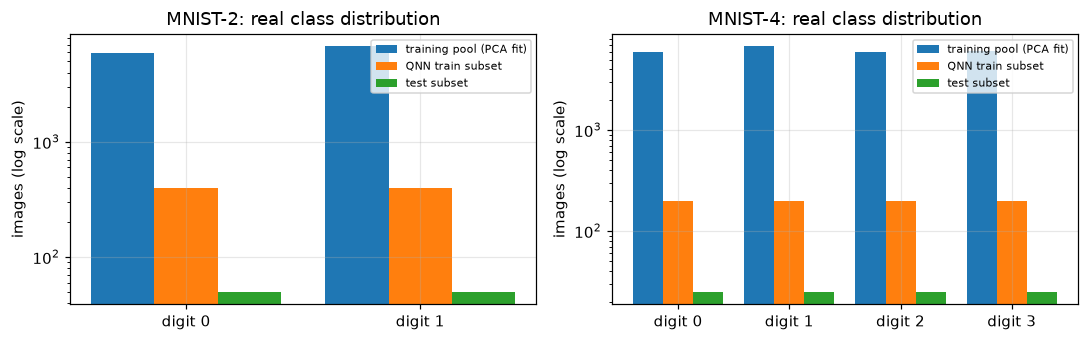

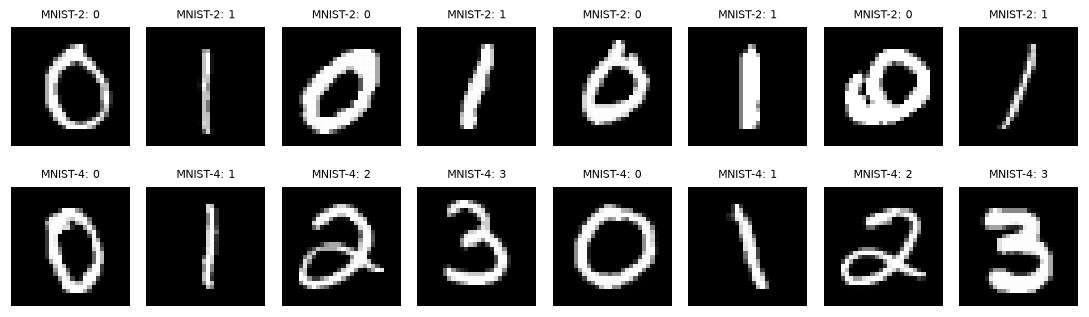

In [6]:
# ---- shapes, feature names, labels and class counts --------------------------------------------
for task, d in DATA.items():
    print(f"=== {task} (digits {d['digits']}) ===")
    print("pixel matrix of the training pool :", d["pool_px"].shape, "| features pixel_0_0 ... pixel_27_27 (784 grey values in [0, 1])")
    print("PCA coordinates / encoding angles :", d["A_pool"].shape, "| features", [f"angle_q{i}" for i in range(N_QUBITS)][:4], "...", f"angle_q{N_QUBITS - 1}")
    for name, y in [("training pool", d["pool_y"]), ("QNN train subset", d["y_tr"]), ("retrain subset", d["y_rt"]), ("test subset", d["y_te"])]:
        vals, cnt = np.unique(y, return_counts=True)
        print(f"  {name:17s}: original labels {dict(zip(vals.tolist(), cnt.tolist()))}")

fig, axes = plt.subplots(1, len(DATA), figsize=(10, 3.2))
for ax, (task, d) in zip(np.atleast_1d(axes), DATA.items()):
    labs = np.array(d["digits"])
    pool_c = [int((d["pool_y"] == c).sum()) for c in labs]
    train_c = [int((d["y_tr"] == c).sum()) for c in labs]
    test_c = [int((d["y_te"] == c).sum()) for c in labs]
    w = 0.27
    ax.bar(np.arange(len(labs)) - w, pool_c, w, label="training pool (PCA fit)")
    ax.bar(np.arange(len(labs)), train_c, w, label="QNN train subset")
    ax.bar(np.arange(len(labs)) + w, test_c, w, label="test subset")
    ax.set_xticks(range(len(labs))); ax.set_xticklabels([f"digit {c}" for c in labs]); ax.set_yscale("log")
    ax.set_title(f"{task}: real class distribution"); ax.set_ylabel("images (log scale)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(DATA), 8, figsize=(10, 1.45 * len(DATA) + 0.3), squeeze=False)
for r, (task, d) in enumerate(DATA.items()):
    for c in range(8):
        cls = d["digits"][c % len(d["digits"])]
        k = np.flatnonzero(d["y_te"] == cls)[c // len(d["digits"])]
        axes[r, c].imshow(d["test_px"][k].reshape(28, 28), cmap="gray"); axes[r, c].axis("off"); axes[r, c].set_title(f"{task}: {cls}", fontsize=7)
plt.tight_layout(); plt.show()

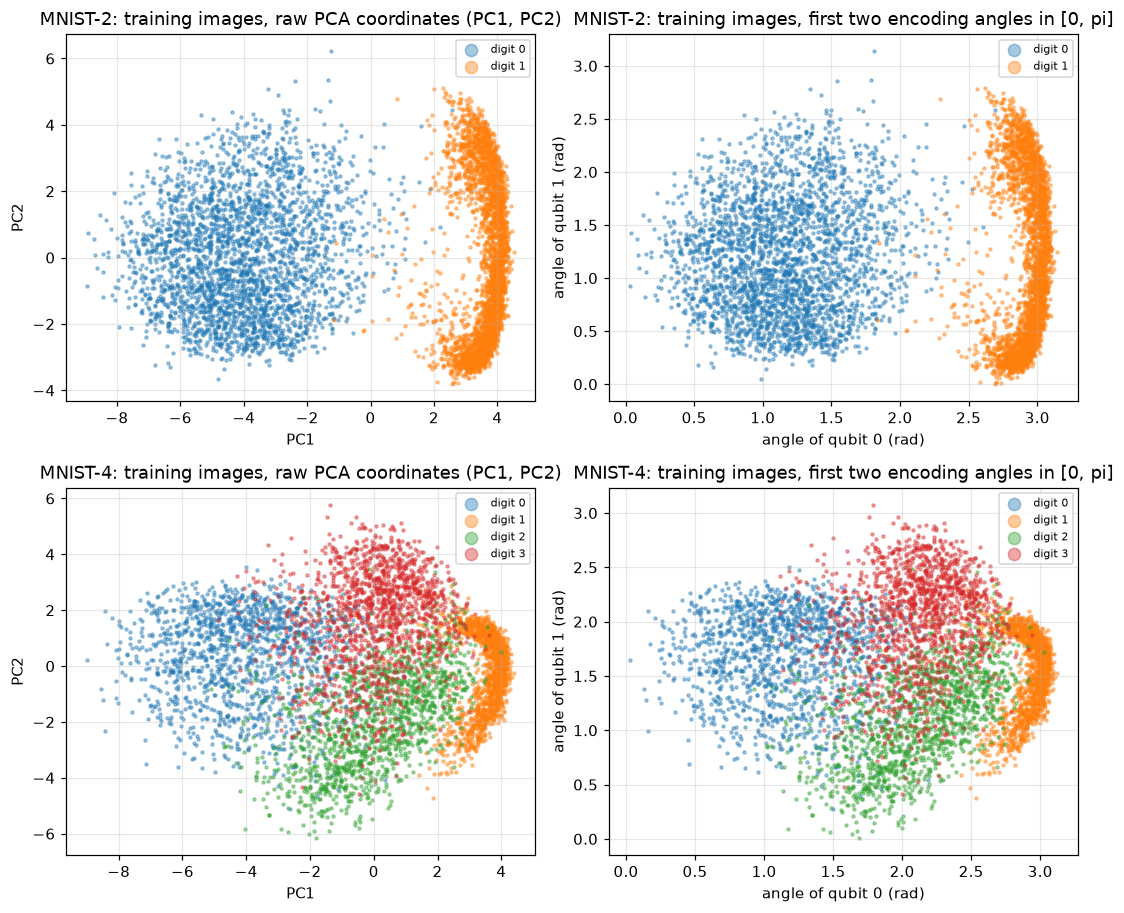

Each point is one real MNIST training image; the colour is its ground-truth digit.


In [7]:
# ---- 2-D scatter of real training images coloured by ground-truth digit ------------------------
cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(len(DATA), 2, figsize=(10, 4.2 * len(DATA)), squeeze=False)
for r, (task, d) in enumerate(DATA.items()):
    show = np.random.default_rng(SEED).choice(len(d["pool_y"]), size=min(6000, len(d["pool_y"])), replace=False)   # random subset of the real training images (readability and file size)
    for c in d["digits"]:
        sel = np.zeros(len(d["pool_y"]), bool); sel[show] = d["pool_y"][show] == c
        axes[r, 0].scatter(d["Z_pool"][sel, 0], d["Z_pool"][sel, 1], s=4, alpha=0.4, color=cmap(c), label=f"digit {c}")
        axes[r, 1].scatter(d["A_pool"][sel, 0], d["A_pool"][sel, 1], s=4, alpha=0.4, color=cmap(c), label=f"digit {c}")
    axes[r, 0].set_title(f"{task}: training images, raw PCA coordinates (PC1, PC2)")
    axes[r, 0].set_xlabel("PC1"); axes[r, 0].set_ylabel("PC2")
    axes[r, 1].set_title(f"{task}: training images, first two encoding angles in [0, pi]")
    axes[r, 1].set_xlabel("angle of qubit 0 (rad)"); axes[r, 1].set_ylabel("angle of qubit 1 (rad)")
    axes[r, 0].legend(markerscale=4, fontsize=7); axes[r, 1].legend(markerscale=4, fontsize=7)
plt.tight_layout(); plt.show()
print("Each point is one real MNIST training image; the colour is its ground-truth digit.")

## 3. Classical baselines on exactly the same inputs

A random forest and an RBF support-vector machine on the same 16 angles (same training subset, same test subset). They show the accuracy ceiling of this 16-number representation. Later the same two models are trained on the poisoned data of the DPBA baseline, to see whether a classical model really gets both high clean accuracy and high attack success, as the paper argues for classical networks.

In [8]:
BASE = {}
rows_b = []
for task, d in DATA.items():
    for label, clf in [("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)),
                       ("SVC (rbf)", SVC(kernel="rbf", C=1.0, random_state=SEED))]:
        t0 = time.time(); clf.fit(d["A_tr"], d["y_tr"]); acc = float((clf.predict(d["A_te"]) == d["y_te"]).mean())
        BASE[(task, label)] = acc
        rows_b.append(dict(task=task, model=label, test_accuracy_pct=100 * acc, train_seconds=round(time.time() - t0, 2)))
print(pd.DataFrame(rows_b).round(2).to_string(index=False))

   task        model  test_accuracy_pct  train_seconds
MNIST-2 RandomForest              100.0           3.85
MNIST-2    SVC (rbf)              100.0           0.05
MNIST-4 RandomForest               96.0           2.96
MNIST-4    SVC (rbf)               98.0           0.06


## 4. The victim QNN and the QTrojan layers

**Victim QNN (Figure 2 and Section 4 of the paper).** 16 qubits, one encoding angle per qubit.

`RY(angle_q)|0>` on every qubit (angle encoding `S_x`) -> [ `Rot` on every qubit -> ring of `CRX(q -> q+1 mod 16)` ] x 2 -> measure.

Per block there are 16 `Rot` gates (3 angles each) and 16 `CRX` gates: 64 angles, 128 in total. The class is read from the measured probabilities of qubit 0 (two classes) or of qubits 0 and 1 (four classes).

**QTrojan layers (Figure 5).** Around `S_x` there are three more rotation layers whose angles are read from the backend configuration file:

| Layer | Gate on every qubit | Benign file | Triggered file |
|---|---|---|---|
| pre-encoding `S-bar` | `RX1` | 0 | pi/2 |
| encoding `S_x` | `RY(angle)` | data | data (but it has no effect) |
| post-encoding `S-tilde` | `RX2` then `RY` | 0, 0 | 3pi/2, theta |

A rotation by 0 is the identity, so with the benign file the circuit is the clean QNN. The configuration file is simulated below as a text file with one calibration line per qubit; the compiler reads the three angles from it.

**Simulation.** PennyLane `lightning.qubit` (C++ state-vector simulator, single precision for training) with adjoint differentiation. For the loss `-log p(true class)` the gradient of one image needs one adjoint pass with the weighted observable `-(1/p_y) |y><y|` on the read-out qubits. The exactness of this simulator is checked against Qiskit in the circuit section that follows.

In [9]:
# ---- the victim QNN, the QTrojan layers and the configuration file -------------------------------
N, NB = N_QUBITS, 2
NPAR = NB * 4 * N                                   # 2 blocks x (16 Rot x 3 + 16 CRX) = 128 trainable angles
DEV = qml.device("lightning.qubit", wires=N, c_dtype=np.complex64)    # training / evaluation (single precision)
DEV128 = qml.device("lightning.qubit", wires=N)                       # double precision, used for exactness checks

def benign_cfg():
    return dict(pre=np.zeros(N), post=np.zeros(N), theta=np.zeros(N))

def trojan_cfg(theta, qubits=None, post=True):
    """Triggered configuration: RX1 = pi/2 on the chosen qubits and (if post) RX2 = 3pi/2, RY = theta."""
    c = benign_cfg()
    for q in (range(N) if qubits is None else qubits):
        c["pre"][q] = np.pi / 2
        if post:
            c["post"][q] = 3 * np.pi / 2
            c["theta"][q] = theta[q]
    return c

def config_text(cfg):
    """The server-specific configuration file: one calibration line per qubit (the trigger hides in these numbers)."""
    return "\n".join(f"q{q}: x_cal_pre={cfg['pre'][q]:.6f} x_cal_post={cfg['post'][q]:.6f} y_cal={cfg['theta'][q]:.6f}" for q in range(N))

def read_config(text):
    """The trusted compiler reads the three calibration angles of every qubit from the file."""
    c = benign_cfg()
    for line in text.strip().splitlines():
        head, rest = line.split(":")
        q = int(head[1:])
        kv = dict(item.split("=") for item in rest.split())
        c["pre"][q], c["post"][q], c["theta"][q] = float(kv["x_cal_pre"]), float(kv["x_cal_post"]), float(kv["y_cal"])
    return c

def ops_for(params, angles, cfg=None):
    """Gate list of the QNN.  cfg=None: the clean circuit as the designer wrote it.  cfg=dict: the circuit with the
    three QTrojan layers (RX1, RX2, RY) whose angles come from the configuration file.  Every simulator call below
    uses this one function, so the circuit that is drawn is the circuit that is executed."""
    p = np.asarray(params).reshape(NB, 4 * N)
    ops = []
    if cfg is not None:
        ops += [qml.RX(cfg["pre"][q], wires=q) for q in range(N)]                    # pre-encoding layer  (S-bar)
    ops += [qml.RY(angles[q], wires=q) for q in range(N)]                            # angle encoding S_x
    if cfg is not None:
        ops += [qml.RX(cfg["post"][q], wires=q) for q in range(N)]                   # post-encoding layer (S-tilde): RX2
        ops += [qml.RY(cfg["theta"][q], wires=q) for q in range(N)]                  #                                  RY(theta)
    for b in range(NB):
        ops += [qml.Rot(p[b, 3 * q], p[b, 3 * q + 1], p[b, 3 * q + 2], wires=q) for q in range(N)]
        ops += [qml.CRX(p[b, 3 * N + q], wires=[q, (q + 1) % N]) for q in range(N)]  # ring-connected CRX layer
    return ops

def read_wires(k):
    return list(range(int(np.ceil(np.log2(k)))))

def probs_batch(params, A, cfg, k, dev=DEV):
    """Measured probability vector (first k outcomes) for every row of A."""
    tapes = [qml.tape.QuantumScript(ops_for(params, a, cfg), [qml.probs(wires=read_wires(k))]) for a in A]
    return np.array([np.asarray(o)[:k] for o in dev.execute(tapes)], dtype=float)

def predict(params, A, k, cfg=None):
    return probs_batch(params, A, cfg, k).argmax(1)

def accuracy(params, A, y, k, cfg=None):
    return float((predict(params, A, k, cfg) == y).mean())

def grad_nll_batch(params, A, y, cfg, k, eps=1e-7):
    """Mean negative log-likelihood of the measured probability of the true class, and its gradient (adjoint method)."""
    P = probs_batch(params, A, cfg, k)
    py = np.clip(P[np.arange(len(y)), y], eps, None)
    n_pre = N if cfg is None else 4 * N                          # index of the first trainable angle in the gate list
    tapes = []
    for a, yy, pp in zip(A, y, py):
        d = np.zeros(2 ** len(read_wires(k))); d[yy] = -1.0 / pp
        obs = qml.Hermitian(np.diag(d), wires=read_wires(k))
        tapes.append(qml.tape.QuantumScript(ops_for(params, a, cfg), [qml.expval(obs)], trainable_params=list(range(n_pre, n_pre + NPAR))))
    jac = DEV.compute_derivatives(tapes, qml.devices.ExecutionConfig(gradient_method="adjoint"))
    return float(-np.mean(np.log(py))), np.mean([np.asarray(j).ravel() for j in jac], axis=0)

class Adam:
    def __init__(self, lr, wd, b1=0.9, b2=0.999, e=1e-8):
        self.lr, self.wd, self.b1, self.b2, self.e, self.t = lr, wd, b1, b2, e, 0
        self.m, self.v = np.zeros(NPAR), np.zeros(NPAR)
    def step(self, params, g, lr=None):
        g = g + self.wd * params                                   # L2 weight decay as in torch.optim.Adam
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * g * g
        mh, vh = self.m / (1 - self.b1 ** self.t), self.v / (1 - self.b2 ** self.t)
        return params - (self.lr if lr is None else lr) * mh / (np.sqrt(vh) + self.e)

def init_params(seed):
    g = np.random.default_rng(seed)
    p = np.zeros((NB, 4 * N))
    p[:, :3 * N] = g.normal(0, 1.0, (NB, 3 * N))                   # CHOICE: Rot angles ~ N(0, 1)
    p[:, 3 * N:] = g.normal(0, 0.5, (NB, N))                       # CHOICE: CRX angles ~ N(0, 0.5)
    return p.ravel()

def train(params, A, y, k, steps, lr, gen, tag="", log_every=10):
    """Adam on the NLL; mini-batches of BATCH images; cosine learning-rate decay to LR_END_FRAC * lr."""
    opt, hist = Adam(lr, WEIGHT_DECAY), []
    for s in range(steps):
        lr_s = lr * (LR_END_FRAC + (1 - LR_END_FRAC) * 0.5 * (1 + math.cos(math.pi * s / max(steps, 1))))
        ib = gen.choice(len(y), size=min(BATCH, len(y)), replace=False)
        loss, g = grad_nll_batch(params, A[ib], y[ib], None, k)
        params = opt.step(params, g, lr_s)
        hist.append(loss)
        if log_every and (s % log_every == 0 or s == steps - 1):
            print(f"   {tag} step {s + 1:3d}/{steps}  batch NLL {loss:.3f}", flush=True)
    return params, hist

def trigger_inputs(A):
    """DPBA trigger: encoding angle pi on one qubit."""
    A = np.array(A, copy=True); A[:, TRIGGER_QUBIT] = TRIGGER_ANGLE
    return A

print("trainable angles:", NPAR, "| configuration values per qubit: 3 (pre, post, theta) =", 3 * N)
cfg_demo = trojan_cfg(np.full(N, 0.7))
assert np.allclose(read_config(config_text(cfg_demo))["theta"], cfg_demo["theta"], atol=1e-6)
print("--- what the attacker changes in the configuration file (qubits 0-3 shown) ---")
a_txt, b_txt = config_text(benign_cfg()).splitlines()[:4], config_text(cfg_demo).splitlines()[:4]
print("\n".join(l for l in difflib.unified_diff(a_txt, b_txt, "config_benign.txt", "config_triggered.txt", lineterm="", n=0)))

trainable angles: 128 | configuration values per qubit: 3 (pre, post, theta) = 48
--- what the attacker changes in the configuration file (qubits 0-3 shown) ---
--- config_benign.txt
+++ config_triggered.txt
@@ -1,4 +1,4 @@
-q0: x_cal_pre=0.000000 x_cal_post=0.000000 y_cal=0.000000
-q1: x_cal_pre=0.000000 x_cal_post=0.000000 y_cal=0.000000
-q2: x_cal_pre=0.000000 x_cal_post=0.000000 y_cal=0.000000
-q3: x_cal_pre=0.000000 x_cal_post=0.000000 y_cal=0.000000
+q0: x_cal_pre=1.570796 x_cal_post=4.712389 y_cal=0.700000
+q1: x_cal_pre=1.570796 x_cal_post=4.712389 y_cal=0.700000
+q2: x_cal_pre=1.570796 x_cal_post=4.712389 y_cal=0.700000
+q3: x_cal_pre=1.570796 x_cal_post=4.712389 y_cal=0.700000


## Quantum Circuit Architecture

Two architectures are executed in this notebook. Both are drawn from the **same gate list** (`ops_for`) that the simulator runs, wrapped in a PennyLane QNode on the `lightning.qubit` device:

* **Clean QNN** (`cfg=None`): angle encoding, two blocks of `Rot` + ring of `CRX`, measurement of qubits 0 and 1. This is the circuit the victim trains.
* **Backdoored QNN** (`cfg=` a configuration): the same circuit with the three QTrojan layers `RX1`, `RX2`, `RY` around the encoding layer. With the benign file all three layers are rotations by 0 (identity); with the triggered file they are `pi/2`, `3pi/2`, `theta`.

Assumptions where the paper is silent: the ring of `CRX` gates is applied in the order q = 0, 1, ..., 15 (control q, target q+1 mod 16) after the `Rot` layer of the same block; `Rot` is PennyLane's `Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)`; the 4-class read-out measures qubits 0 and 1, the 2-class read-out qubit 0.

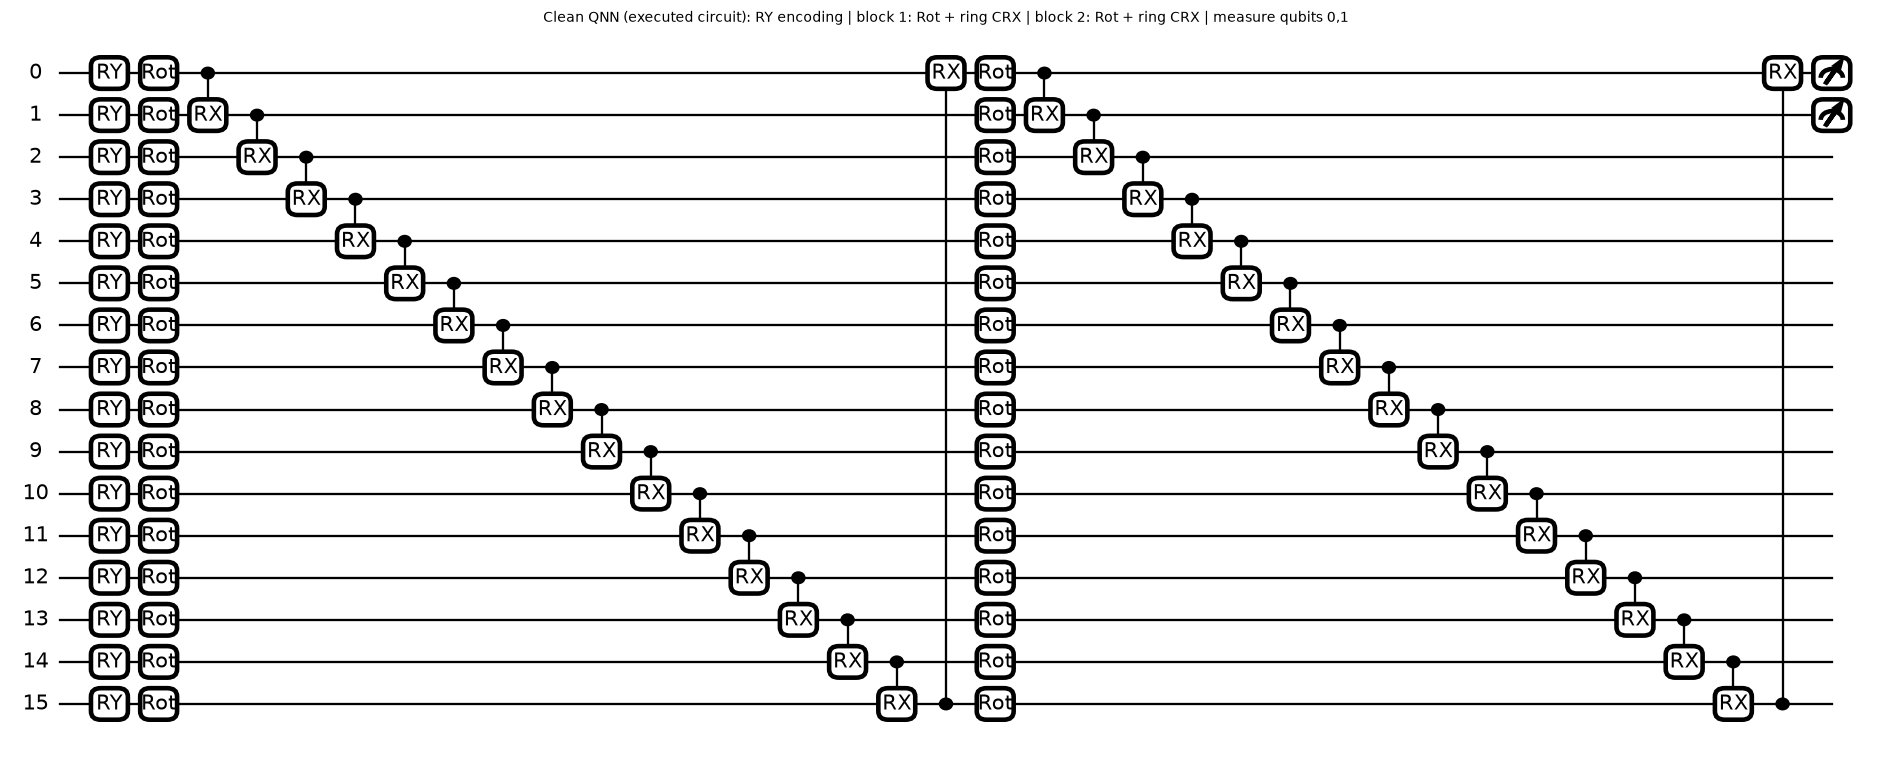

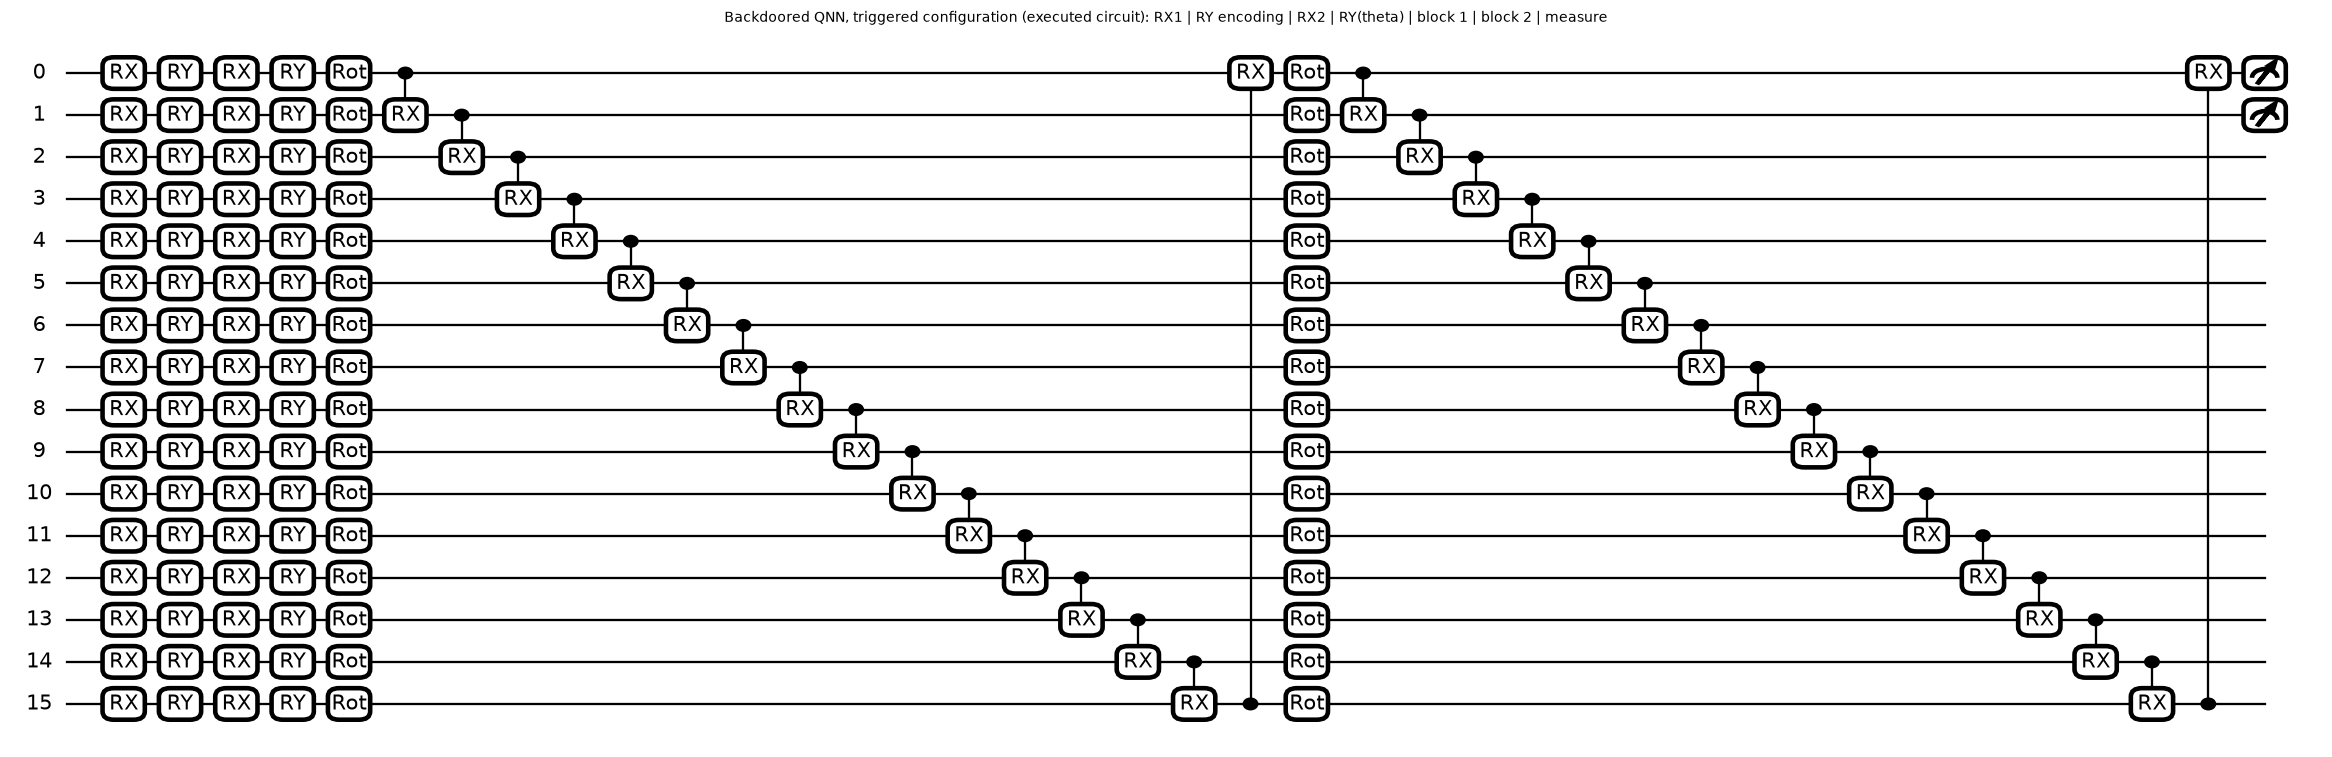

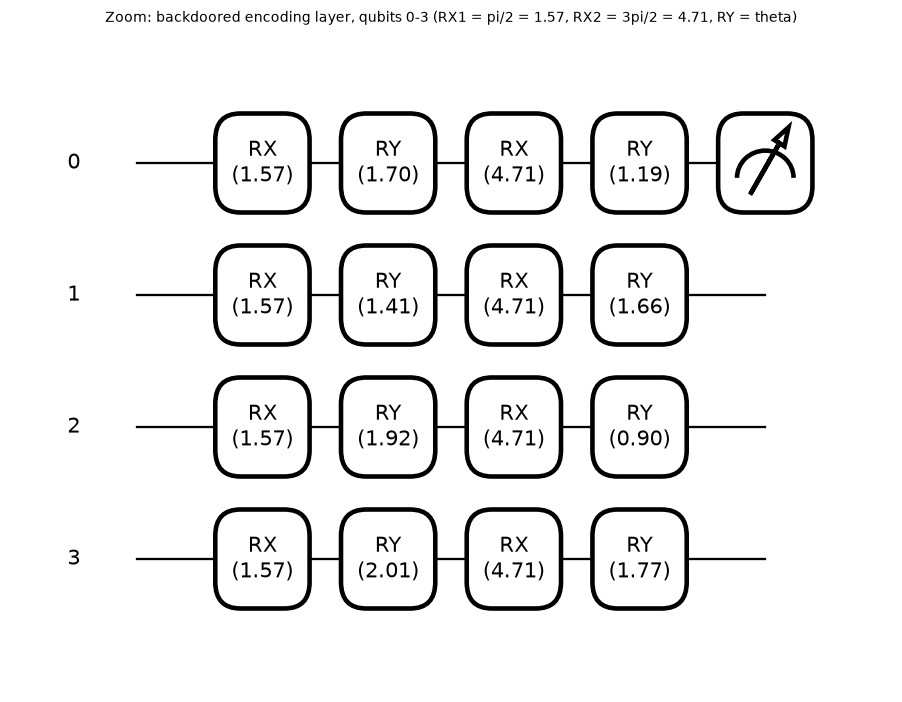

In [10]:
def make_qnode(cfg, k):
    @qml.qnode(DEV)
    def f(params, angles):
        ops_for(params, angles, cfg)              # the operators are queued by creation, exactly the executed gate list
        return qml.probs(wires=read_wires(k))
    return f

p_demo = init_params(123)
a_demo = DATA["MNIST-4"]["A_te"][0]
theta_demo = DATA["MNIST-4"]["A_tr"][DATA["MNIST-4"]["y_tr"] == 0].mean(0)
qn_clean, qn_trojan = make_qnode(None, 4), make_qnode(trojan_cfg(theta_demo), 4)

fig, ax = qml.draw_mpl(qn_clean, show_all_wires=True)(p_demo, a_demo)
fig.set_size_inches(17, 6.5); ax.set_title("Clean QNN (executed circuit): RY encoding | block 1: Rot + ring CRX | block 2: Rot + ring CRX | measure qubits 0,1", fontsize=9)
plt.show()
fig, ax = qml.draw_mpl(qn_trojan, show_all_wires=True)(p_demo, a_demo)
fig.set_size_inches(21, 6.5); ax.set_title("Backdoored QNN, triggered configuration (executed circuit): RX1 | RY encoding | RX2 | RY(theta) | block 1 | block 2 | measure", fontsize=9)
plt.show()

# zoom on the QTrojan layers of qubits 0-3 with their angles printed (a slice of the same gate list)
zoom_ops = [op for op in ops_for(p_demo, a_demo, trojan_cfg(theta_demo))[:4 * N] if op.wires[0] < 4]   # built outside a QNode: not queued
@qml.qnode(DEV)
def zoom_encoding():
    for op in zoom_ops:
        qml.apply(op)
    return qml.probs(wires=[0])
fig, ax = qml.draw_mpl(zoom_encoding, show_all_wires=False, decimals=2)()
fig.set_size_inches(8, 6); ax.set_title("Zoom: backdoored encoding layer, qubits 0-3 (RX1 = pi/2 = 1.57, RX2 = 3pi/2 = 4.71, RY = theta)", fontsize=9)
plt.show()

In [11]:
# ---- qubit count, depth, trainable parameters ---------------------------------------------------
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

def qiskit_circuit(params, angles, cfg=None):
    """The same circuit written independently in Qiskit (Rot = RZ(phi), RY(theta), RZ(omega) in this order)."""
    p = np.asarray(params).reshape(NB, 4 * N)
    qc = QuantumCircuit(N)
    if cfg is not None:
        for q in range(N): qc.rx(float(cfg["pre"][q]), q)
    for q in range(N): qc.ry(float(angles[q]), q)
    if cfg is not None:
        for q in range(N): qc.rx(float(cfg["post"][q]), q)
        for q in range(N): qc.ry(float(cfg["theta"][q]), q)
    for b in range(NB):
        for q in range(N):
            qc.rz(float(p[b, 3 * q]), q); qc.ry(float(p[b, 3 * q + 1]), q); qc.rz(float(p[b, 3 * q + 2]), q)
        for q in range(N):
            qc.crx(float(p[b, 3 * N + q]), q, (q + 1) % N)
    return qc

def qiskit_probs(sv, k):
    """Read-out probabilities of a Qiskit Statevector in PennyLane's bit order."""
    pr = sv.probabilities(read_wires(k))                                                # Qiskit: wire 0 = least significant bit
    nb = len(read_wires(k))
    rev = [int(format(i, f"0{nb}b")[::-1], 2) for i in range(2 ** nb)]                  # PennyLane: wire 0 = most significant bit
    return pr[rev][:k]

rows = []
for name, cfg_, qn in [("clean QNN", None, qn_clean), ("backdoored QNN (triggered)", trojan_cfg(theta_demo), qn_trojan)]:
    tape = qml.tape.QuantumScript(ops_for(p_demo, a_demo, cfg_), [qml.probs(wires=[0, 1])])
    qc = qiskit_circuit(p_demo, a_demo, cfg_)
    n_train = len(p_demo)                                  # only the 128 Rot/CRX angles are trained; encoding/trojan angles are inputs/config
    rows.append(dict(architecture=name, qubits=N, gates_pennylane=len(tape.operations), depth_pennylane=tape.graph.get_depth(),
                     depth_qiskit_decomposed=qc.depth(), trainable_angles=n_train,
                     config_angles=0 if cfg_ is None else 3 * N, read_out="qubits 0,1 (4 classes)"))
print(pd.DataFrame(rows).to_string(index=False))
print("PennyLane depth counts Rot as one gate; the Qiskit circuit has Rot decomposed into RZ RY RZ.")

              architecture  qubits  gates_pennylane  depth_pennylane  depth_qiskit_decomposed  trainable_angles  config_angles               read_out
                 clean QNN      16               80               35                       39               128              0 qubits 0,1 (4 classes)
backdoored QNN (triggered)      16              128               38                       42               128             48 qubits 0,1 (4 classes)
PennyLane depth counts Rot as one gate; the Qiskit circuit has Rot decomposed into RZ RY RZ.


### Is the simulator the circuit we drew? Cross-check against Qiskit

Three checks, all must pass before any number below is trusted: (1) the PennyLane QNode of the drawing equals the tape executed during training; (2) the single-precision training device equals the double-precision device; (3) the independent Qiskit circuit gives the same read-out probabilities for the clean circuit, the benign configuration, the full QTrojan and a partial QTrojan.

In [12]:
gen_chk = np.random.default_rng(7)
d4 = DATA["MNIST-4"]
rows = []
for trial in range(2):
    pr = init_params(100 + trial) + 0.0
    A_chk = d4["A_te"][trial * 2: trial * 2 + 2]
    cfgs = [("clean", None), ("benign config", benign_cfg()), ("full QTrojan", trojan_cfg(gen_chk.uniform(0, np.pi, N))),
            ("partial QTrojan (qubits 0-1)", trojan_cfg(None, qubits=[0, 1], post=False))]
    for name, cfg_ in cfgs:
        svs = [Statevector(qiskit_circuit(pr, a, cfg_)) for a in A_chk]                  # one Qiskit simulation per image
        for k in (2, 4):
            ref = np.array([qiskit_probs(sv, k) for sv in svs])
            p64 = probs_batch(pr, A_chk, cfg_, k)
            p128 = probs_batch(pr, A_chk, cfg_, k, dev=DEV128)
            qn = np.array([np.asarray(make_qnode(cfg_, k)(pr, a), dtype=float)[:k] for a in A_chk])
            rows.append(dict(config=name, k=k, qnode_vs_tape=np.abs(qn - p64).max(), f32_vs_f64=np.abs(p64 - p128).max(),
                             pennylane_vs_qiskit=np.abs(p128 - ref).max()))
df_chk = pd.DataFrame(rows).groupby(["config", "k"]).max().reset_index()
print(df_chk.to_string(index=False, float_format=lambda v: f"{v:.1e}"))
assert df_chk.qnode_vs_tape.max() < 1e-5 and df_chk.f32_vs_f64.max() < 2e-4 and df_chk.pennylane_vs_qiskit.max() < 1e-9
print("PASS: the drawn circuit, the training simulator and Qiskit agree.")

                      config  k  qnode_vs_tape  f32_vs_f64  pennylane_vs_qiskit
               benign config  2        0.0e+00     2.5e-05              6.2e-15
               benign config  4        0.0e+00     9.2e-06              1.9e-15
                       clean  2        0.0e+00     2.5e-05              6.2e-15
                       clean  4        0.0e+00     9.2e-06              1.9e-15
                full QTrojan  2        0.0e+00     1.8e-05              2.9e-15
                full QTrojan  4        0.0e+00     5.6e-06              2.1e-15
partial QTrojan (qubits 0-1)  2        0.0e+00     4.1e-05              4.1e-15
partial QTrojan (qubits 0-1)  4        0.0e+00     1.2e-05              6.1e-15
PASS: the drawn circuit, the training simulator and Qiskit agree.


### Why the input disappears: the encoding layer on the Bloch sphere (paper Figure 5b)

One qubit, four stages. Stage 1 (`RX1(pi/2)`) moves `|0>` to the `-y` pole. Stage 2 (`S_x = RY(angle)`) rotates around the y axis, which leaves the `-y` pole where it is, whatever the angle. Stage 3 (`RX2(3pi/2)`) completes a full `RX(2pi)` and brings the qubit back to `|0>`. Stage 4 (`RY(theta)`) writes the attacker's state. Without the backdoor the same `S_x` moves the qubit along the great circle `y = 0` according to the data.

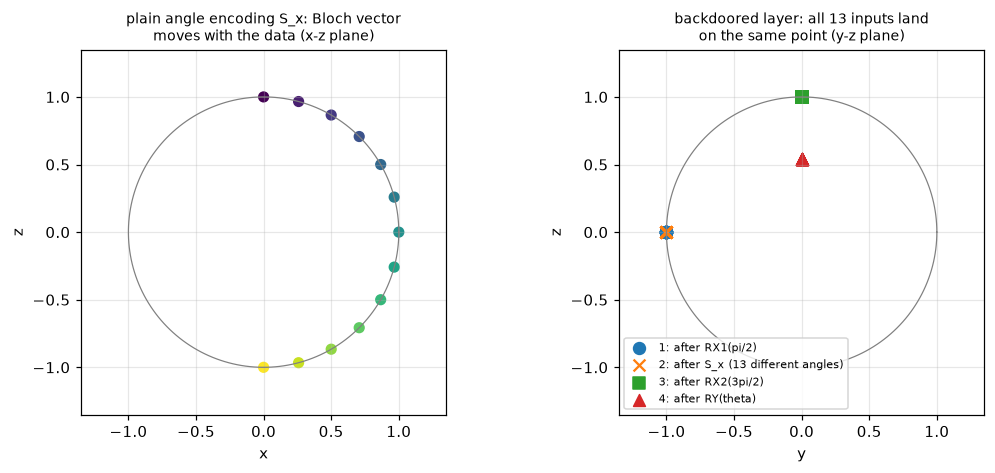

max Bloch-vector spread over the 13 input angles per stage: {1: 0.0, 2: 0.0, 3: 0.0, 4: 0.0}


In [13]:
def bloch(circ):
    sv = Statevector(circ)
    from qiskit.quantum_info import Pauli
    return np.array([sv.expectation_value(Pauli(c)).real for c in "XYZ"])

xs = np.linspace(0, np.pi, 13)
theta_1q = 1.0
st = {1: [], 2: [], 3: [], 4: [], "plain": []}
for x in xs:
    c = QuantumCircuit(1); c.rx(np.pi / 2, 0); st[1].append(bloch(c))
    c.ry(float(x), 0); st[2].append(bloch(c))
    c.rx(3 * np.pi / 2, 0); st[3].append(bloch(c))
    c.ry(theta_1q, 0); st[4].append(bloch(c))
    c0 = QuantumCircuit(1); c0.ry(float(x), 0); st["plain"].append(bloch(c0))
st = {k: np.array(v) for k, v in st.items()}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
tt = np.linspace(0, 2 * np.pi, 200)
for ax in axes:
    ax.plot(np.cos(tt), np.sin(tt), color="gray", lw=0.8); ax.set_aspect("equal"); ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35)
axes[0].scatter(st["plain"][:, 0], st["plain"][:, 2], c=xs, cmap="viridis", s=40)
axes[0].set_title("plain angle encoding S_x: Bloch vector\nmoves with the data (x-z plane)", fontsize=9); axes[0].set_xlabel("x"); axes[0].set_ylabel("z")
for key, mk, col, lab in [(1, "o", "C0", "1: after RX1(pi/2)"), (2, "x", "C1", "2: after S_x (13 different angles)"), (3, "s", "C2", "3: after RX2(3pi/2)"), (4, "^", "C3", "4: after RY(theta)")]:
    axes[1].scatter(st[key][:, 1], st[key][:, 2], marker=mk, color=col, s=60, label=lab)
axes[1].set_title("backdoored layer: all 13 inputs land\non the same point (y-z plane)", fontsize=9); axes[1].set_xlabel("y"); axes[1].set_ylabel("z"); axes[1].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()
spread = {k: float(np.abs(st[k] - st[k][0]).max()) for k in (1, 2, 3, 4)}
print("max Bloch-vector spread over the 13 input angles per stage:", {k: round(v, 6) for k, v in spread.items()})
assert max(spread.values()) < 1e-9 and np.abs(st["plain"] - st["plain"][0]).max() > 1.0

### The whole 16-qubit QNN no longer depends on the input (double precision check)

With the triggered file the state entering the variational block is `RY(theta_q)|0>` on every qubit, which is exactly what the *clean* circuit would produce for the input `angle = theta`. We check this on random trained-like parameters: the output probabilities of the triggered circuit are identical for random inputs, and equal to the clean circuit evaluated at `angle = theta`.

In [14]:
gen_i = np.random.default_rng(11)
pr = init_params(5)
theta_r = gen_i.uniform(0, np.pi, N)
cfg_r = trojan_cfg(theta_r)
X_rand = np.vstack([gen_i.uniform(0, np.pi, (6, N)), DATA["MNIST-4"]["A_te"][:6]])      # random angles and real test images
P_trig = probs_batch(pr, X_rand, cfg_r, 4, dev=DEV128)
P_fix = probs_batch(pr, theta_r[None], None, 4, dev=DEV128)
print("max spread of the triggered output over 12 different inputs :", f"{np.abs(P_trig - P_trig[0]).max():.1e}")
print("max |triggered(x) - clean(angle = theta)|                    :", f"{np.abs(P_trig - P_fix).max():.1e}")
assert np.abs(P_trig - P_trig[0]).max() < 1e-10 and np.abs(P_trig - P_fix).max() < 1e-10
print("PASS: with the trigger the QNN output is input-independent and equals the clean QNN on the fixed state theta.")

max spread of the triggered output over 12 different inputs : 5.6e-16
max |triggered(x) - clean(angle = theta)|                    : 8.9e-16
PASS: with the trigger the QNN output is input-independent and equals the clean QNN on the fixed state theta.


## 5. Training the clean QNN (what the victim does)

The victim trains the 128 variational angles on their own data with the benign configuration; the QTrojan layers are dormant (identity), so training is the same as for the clean circuit and we train the layer-free circuit (this is exactly equivalent, see the benign-configuration check below). Hyper-parameters are in the configuration cell; per-step progress is printed. Several model seeds (initial angles and mini-batch order) give a mean and a standard deviation.

   [MNIST-2 seed 0] clean step   1/12  batch NLL 0.473


   [MNIST-2 seed 0] clean step   4/12  batch NLL 0.126


   [MNIST-2 seed 0] clean step   7/12  batch NLL 0.289


   [MNIST-2 seed 0] clean step  10/12  batch NLL 0.243


   [MNIST-2 seed 0] clean step  12/12  batch NLL 0.186


...

   [MNIST-4 seed 0] clean step   6/20  batch NLL 1.308


   [MNIST-4 seed 0] clean step  11/20  batch NLL 0.878


   [MNIST-4 seed 0] clean step  16/20  batch NLL 1.749


   [MNIST-4 seed 0] clean step  20/20  batch NLL 1.049


[MNIST-4 seed 0] clean QNN test accuracy 41.0 % (145 s)


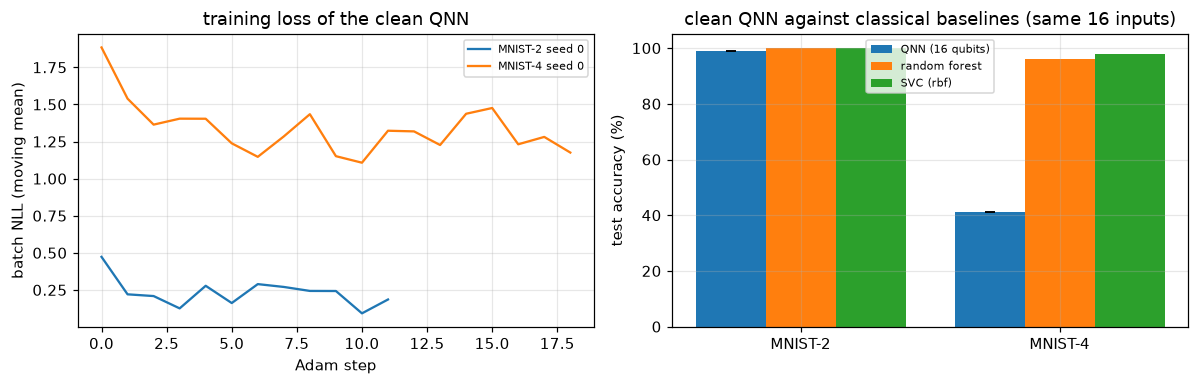

         mean  std
task              
MNIST-2  99.0  NaN
MNIST-4  41.0  NaN


In [15]:
MODELS, HIST, TRAIN_SEC, rows_clean = {}, {}, {}, []
for task, d in DATA.items():
    for seed in MODEL_SEEDS:
        gen = np.random.default_rng(1000 * seed + 17)
        t0 = time.time()
        params, hist = train(init_params(seed), d["A_tr"], d["y_tr"], d["K"], STEPS_CLEAN[task], LR, gen, tag=f"[{task} seed {seed}] clean",
                             log_every=max(1, STEPS_CLEAN[task] // 4))
        MODELS[(task, seed)], HIST[(task, seed)] = params, hist
        acc = accuracy(params, d["A_te"], d["y_te"], d["K"])
        TRAIN_SEC[(task, seed)] = time.time() - t0
        rows_clean.append(dict(task=task, seed=seed, steps=STEPS_CLEAN[task], clean_test_acc_pct=100 * acc, seconds=round(TRAIN_SEC[(task, seed)], 1)))
        print(f"[{task} seed {seed}] clean QNN test accuracy {100 * acc:.1f} % ({TRAIN_SEC[(task, seed)]:.0f} s)", flush=True)
df_clean = pd.DataFrame(rows_clean)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for task in DATA:
    for seed in MODEL_SEEDS:
        h = np.array(HIST[(task, seed)]); w = max(1, len(h) // 8)
        axes[0].plot(np.convolve(h, np.ones(w) / w, mode="valid"), label=f"{task} seed {seed}")
axes[0].set_xlabel("Adam step"); axes[0].set_ylabel("batch NLL (moving mean)"); axes[0].set_title("training loss of the clean QNN"); axes[0].legend(fontsize=7)
summ = df_clean.groupby("task").clean_test_acc_pct.agg(["mean", "std"]).fillna(0)
x = np.arange(len(DATA))
axes[1].bar(x - 0.27, [summ.loc[t, "mean"] for t in DATA], 0.27, yerr=[summ.loc[t, "std"] for t in DATA], label="QNN (16 qubits)", capsize=3)
axes[1].bar(x, [100 * BASE[(t, "RandomForest")] for t in DATA], 0.27, label="random forest")
axes[1].bar(x + 0.27, [100 * BASE[(t, "SVC (rbf)")] for t in DATA], 0.27, label="SVC (rbf)")
axes[1].set_xticks(x); axes[1].set_xticklabels(list(DATA)); axes[1].set_ylim(0, 105); axes[1].set_ylabel("test accuracy (%)")
axes[1].set_title("clean QNN against classical baselines (same 16 inputs)"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(df_clean.groupby("task").clean_test_acc_pct.agg(["mean", "std"]).round(2))

## 6. Full QTrojan: clean data accuracy and attack success rate

**CDA.** With the benign file the three extra layers are rotations by 0. We measure the accuracy of the circuit *with* the dormant layers and compare it with the layer-free circuit: the read-out probabilities must be identical.

**ASR.** With the triggered file the state entering the variational block is the fixed product state `RY(theta_q)|0>`, so the output is the same for every image (verified above in double precision, and re-measured here on real test images for every model). The attack therefore succeeds (ASR = 100 %) exactly when the clean model assigns the fixed state to the target class, and fails (ASR = 0 %) otherwise: the whole question is how the attacker picks `theta`. Three attackers are compared:

* **prototype attacker (main):** `theta_q` = mean encoding angle of the target class in a small public sample of that class (here: the training subset);
* **data-free attacker:** random `theta` (no knowledge of the data or the model);
* **white-box attacker:** knows the trained weights and tries many `theta` candidates; this is an upper bound that the paper's threat model does not grant.

The headline number is the mean over all possible target classes.

Fixed-state check: max output spread over the probe images = 7.7e-07 (float32 simulator)
Dormant layers: same predictions as the layer-free circuit for every model: True | max probability difference 0.0e+00

Prototype attacker, ASR per target class (mean over seeds):
target       0      1      2      3
task                               
MNIST-2  100.0  100.0    NaN    NaN
MNIST-4    0.0    0.0  100.0  100.0

Data-free (random theta) and white-box attackers:
         random_theta_ASR_pct  whitebox_targets_reachable_pct
task                                                         
MNIST-2                  50.0                           100.0
MNIST-4                  25.0                            75.0


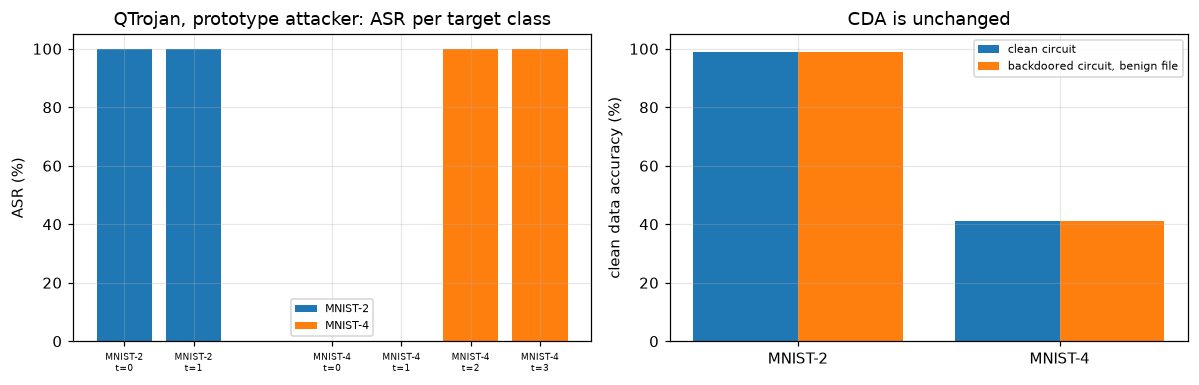

In [16]:
def prototype_theta(d, t):
    return d["A_tr"][d["y_tr"] == t].mean(0)           # CHOICE: the attacker's state = class-mean encoding angles

QT_ROWS, QT_THETA, qt_summary = [], {}, []
for task, d in DATA.items():
    k = d["K"]
    for seed in MODEL_SEEDS:
        params = MODELS[(task, seed)]
        # --- CDA with dormant layers vs layer-free circuit
        P_clean, P_dorm = probs_batch(params, d["A_te"], None, k), probs_batch(params, d["A_te"], benign_cfg(), k)
        cda_clean, cda_dorm = float((P_clean.argmax(1) == d["y_te"]).mean()), float((P_dorm.argmax(1) == d["y_te"]).mean())
        same_pred = bool((P_clean.argmax(1) == P_dorm.argmax(1)).all())
        # --- prototype attacker, every target class; measured on real test images
        probe = d["A_te"][:N_ASR_PROBE]
        for t in range(k):
            theta = prototype_theta(d, t); QT_THETA[(task, t)] = theta
            P = probs_batch(params, probe, trojan_cfg(theta), k)
            QT_ROWS.append(dict(task=task, seed=seed, target=t, ASR_pct=100 * float((P.argmax(1) == t).mean()),
                                output_spread=float(np.abs(P - P[0]).max()), CDA_clean=100 * cda_clean, CDA_dormant=100 * cda_dorm,
                                same_predictions=same_pred, max_prob_diff=float(np.abs(P_clean - P_dorm).max())))
        # --- data-free attacker (random theta) and white-box attacker, one image each: the output is input-independent
        gen_t = np.random.default_rng(5000 + seed)
        cls = np.array([probs_batch(params, d["A_te"][:1], trojan_cfg(gen_t.uniform(0, np.pi, N)), k).argmax(1)[0] for _ in range(N_RANDOM_THETA)])
        hit = np.bincount(cls, minlength=k) / len(cls)
        proto_hits = [QT_ROWS[-k + t]["ASR_pct"] > 0 for t in range(k)]              # the k prototype candidates just evaluated
        reach = np.mean([bool((cls == t).any() or proto_hits[t]) for t in range(k)])  # white-box pool = random draws + prototypes
        qt_summary.append(dict(task=task, seed=seed, random_theta_ASR_pct=100 * float(hit.mean()), random_theta_class_shares=np.round(hit, 2).tolist(),
                               whitebox_targets_reachable_pct=100 * float(reach)))
df_qt = pd.DataFrame(QT_ROWS)
df_qts = pd.DataFrame(qt_summary)
print("Fixed-state check: max output spread over the probe images =", f"{df_qt.output_spread.max():.1e}", "(float32 simulator)")
print("Dormant layers: same predictions as the layer-free circuit for every model:", bool(df_qt.same_predictions.all()),
      "| max probability difference", f"{df_qt.max_prob_diff.max():.1e}")
print("\nPrototype attacker, ASR per target class (mean over seeds):")
print(df_qt.pivot_table(index="task", columns="target", values="ASR_pct", aggfunc="mean").round(1).to_string())
print("\nData-free (random theta) and white-box attackers:")
print(df_qts.groupby("task").agg(random_theta_ASR_pct=("random_theta_ASR_pct", "mean"), whitebox_targets_reachable_pct=("whitebox_targets_reachable_pct", "mean")).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
tp = df_qt.groupby(["task", "target"]).ASR_pct.mean().reset_index()
pos, ticks, labels = 0, [], []
for task in DATA:
    sub = tp[tp.task == task]
    axes[0].bar(pos + np.arange(len(sub)), sub.ASR_pct, label=task)
    ticks += list(pos + np.arange(len(sub))); labels += [f"{task}\nt={t}" for t in sub.target]
    pos += len(sub) + 1
axes[0].set_xticks(ticks); axes[0].set_xticklabels(labels, fontsize=6)
axes[0].set_ylim(0, 105); axes[0].set_ylabel("ASR (%)"); axes[0].set_title("QTrojan, prototype attacker: ASR per target class"); axes[0].legend(fontsize=7)
cd = df_qt.groupby("task")[["CDA_clean", "CDA_dormant"]].mean()
x = np.arange(len(cd))
axes[1].bar(x - 0.2, cd.CDA_clean, 0.4, label="clean circuit"); axes[1].bar(x + 0.2, cd.CDA_dormant, 0.4, label="backdoored circuit, benign file")
axes[1].set_xticks(x); axes[1].set_xticklabels(cd.index); axes[1].set_ylim(0, 105); axes[1].set_ylabel("clean data accuracy (%)"); axes[1].set_title("CDA is unchanged"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. Partial QTrojan (paper Table 3): pre-encoding layer on 1 to 4 qubits only

Only `RX1(pi/2)` is added, on m qubits; no post-encoding layer. Those m qubits are pinned to the `-y` pole whatever the image is, so the input loses m of its 16 numbers, and the circuit is no longer constant: the remaining 16 - m angles still carry data. Nothing writes a target state, so no target is "predefined": we report the share of test images predicted as each class and the best target. For the first-m-qubits subset the read-out qubits (0, 1) are among the pinned ones; in the full run two random qubit subsets (model seed 0) show how much this matters.

[MNIST-2 seed 0] partial QTrojan done


[MNIST-4 seed 0] partial QTrojan done


Partial QTrojan, first m qubits, ASR of the best target class (%), mean over seeds:
m           1      2      3      4
task                              
MNIST-2  78.0   75.0   75.0   75.0
MNIST-4  66.0  100.0  100.0  100.0
Same, target class fixed to class 0 (%):
m           1     2     3     4
task                           
MNIST-2  22.0  75.0  75.0  75.0
MNIST-4   0.0   0.0   0.0   0.0


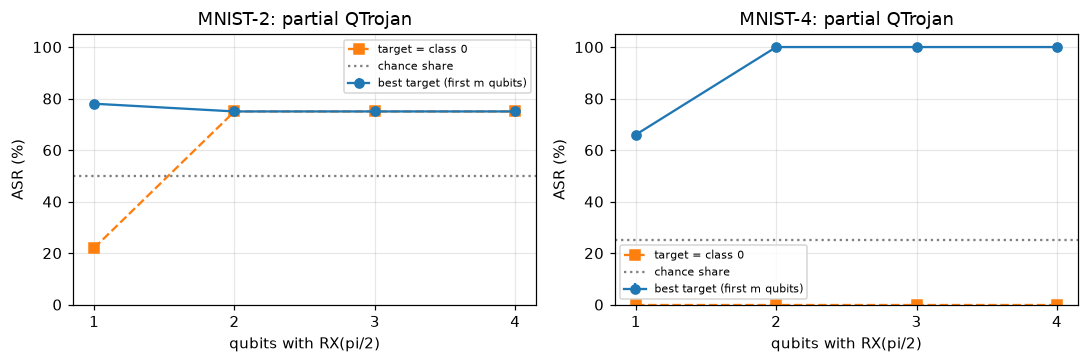

In [17]:
PART_ROWS = []
for task, d in DATA.items():
    k = d["K"]
    for seed in MODEL_SEEDS:
        params = MODELS[(task, seed)]
        subsets = [("first m", lambda m: list(range(m)))]
        if seed == MODEL_SEEDS[0]:
            for r_ in range(N_PARTIAL_RANDOM_SUBSETS):
                gp = np.random.default_rng(900 + r_)
                subsets.append((f"random subset {r_ + 1}", (lambda m, gp=gp: sorted(gp.choice(N, size=m, replace=False).tolist()))))
        for sname, fn in subsets:
            for m in PARTIAL_M:
                qs = fn(m)
                pred = predict(params, d["A_te"], k, trojan_cfg(None, qubits=qs, post=False))
                share = np.bincount(pred, minlength=k) / len(pred)
                PART_ROWS.append(dict(task=task, seed=seed, subset=sname, m=m, qubits=str(qs), ASR_best_target_pct=100 * float(share.max()),
                                      best_target=int(share.argmax()), ASR_target0_pct=100 * float(share[0]),
                                      CDA_dormant_unchanged=True))
        print(f"[{task} seed {seed}] partial QTrojan done", flush=True)
df_part = pd.DataFrame(PART_ROWS)
first = df_part[df_part.subset == "first m"]
print("Partial QTrojan, first m qubits, ASR of the best target class (%), mean over seeds:")
print(first.pivot_table(index="task", columns="m", values="ASR_best_target_pct", aggfunc="mean").round(1).to_string())
print("Same, target class fixed to class 0 (%):")
print(first.pivot_table(index="task", columns="m", values="ASR_target0_pct", aggfunc="mean").round(1).to_string())
if N_PARTIAL_RANDOM_SUBSETS:
    print("Random qubit subsets (model seed 0), ASR of the best target (%):")
    print(df_part[df_part.subset != "first m"].pivot_table(index=["task", "subset"], columns="m", values="ASR_best_target_pct").round(1).to_string())

fig, axes = plt.subplots(1, len(DATA), figsize=(10, 3.4))
for ax, task in zip(np.atleast_1d(axes), DATA):
    s = first[first.task == task].groupby("m").ASR_best_target_pct.agg(["mean", "std"]).fillna(0)
    ax.errorbar(s.index, s["mean"], yerr=s["std"], marker="o", label="best target (first m qubits)")
    s0 = first[first.task == task].groupby("m").ASR_target0_pct.mean()
    ax.plot(s0.index, s0.values, marker="s", ls="--", label="target = class 0")
    ax.axhline(100 / DATA[task]["K"], color="gray", ls=":", label="chance share")
    ax.set_ylim(0, 105); ax.set_xticks(PARTIAL_M); ax.set_xlabel("qubits with RX(pi/2)"); ax.set_ylabel("ASR (%)"); ax.set_title(f"{task}: partial QTrojan"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. The baseline: data-poisoning backdoor (DPBA) on the same QNN

BadNets-style poisoning with a **1-qubit trigger** (encoding angle pi on qubit 15, 6.25 % of the input). `POISON_FRAC` of the training subset is replaced by triggered copies of non-target images labelled with the target class (class 0), and the QNN is trained from scratch on this mix with the same optimiser and a larger step budget than the clean model (`STEPS_DPBA`). CDA is the accuracy on clean test images; ASR is the share of triggered test images (all of them, as the paper defines it) predicted as the target; the share over non-target images is printed too. A random forest and an SVC are trained on the same poisoned set: the paper argues that classical models achieve both goals while the shallow QNN does not.

In [18]:
def poison_set(A, y, gen):
    cand = np.flatnonzero(y != DPBA_TARGET)
    idx = gen.choice(cand, size=int(round(POISON_FRAC * len(y))), replace=False)
    A2, y2 = A.copy(), y.copy()
    A2[idx, TRIGGER_QUBIT] = TRIGGER_ANGLE; y2[idx] = DPBA_TARGET
    return A2, y2, idx

DPBA_MODELS, DPBA_ROWS, CLS_ROWS = {}, [], []
for task, d in DATA.items():
    k = d["K"]
    A_trig, nt = trigger_inputs(d["A_te"]), d["y_te"] != DPBA_TARGET
    for seed in MODEL_SEEDS:
        gen = np.random.default_rng(2000 * seed + 29)
        A2, y2, idx = poison_set(d["A_tr"], d["y_tr"], gen)
        t0 = time.time()
        params, hist = train(init_params(seed), A2, y2, k, STEPS_DPBA[task], LR, gen, tag=f"[{task} seed {seed}] DPBA", log_every=max(1, STEPS_DPBA[task] // 4))
        DPBA_MODELS[(task, seed)] = params
        pred_c, pred_t = predict(params, d["A_te"], k), predict(params, A_trig, k)
        DPBA_ROWS.append(dict(task=task, seed=seed, poisoned=len(idx), CDA_pct=100 * float((pred_c == d["y_te"]).mean()),
                              ASR_pct=100 * float((pred_t == DPBA_TARGET).mean()), ASR_nontarget_pct=100 * float((pred_t[nt] == DPBA_TARGET).mean()),
                              seconds=round(time.time() - t0, 1)))
        print(f"[{task} seed {seed}] DPBA QNN: CDA {DPBA_ROWS[-1]['CDA_pct']:.1f} %, ASR {DPBA_ROWS[-1]['ASR_pct']:.1f} % "
              f"(non-target images {DPBA_ROWS[-1]['ASR_nontarget_pct']:.1f} %)", flush=True)
    for label, clf in [("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)), ("SVC (rbf)", SVC(kernel="rbf", C=1.0, random_state=SEED))]:
        A2, y2, _ = poison_set(d["A_tr"], d["y_tr"], np.random.default_rng(31))
        clf.fit(A2, y2)
        CLS_ROWS.append(dict(task=task, model=label, CDA_pct=100 * float((clf.predict(d["A_te"]) == d["y_te"]).mean()),
                             ASR_pct=100 * float((clf.predict(A_trig) == DPBA_TARGET).mean())))
df_dpba, df_cls = pd.DataFrame(DPBA_ROWS), pd.DataFrame(CLS_ROWS)
print("\nDPBA on the QNN (mean over seeds):"); print(df_dpba.groupby("task")[["CDA_pct", "ASR_pct", "ASR_nontarget_pct"]].mean().round(1).to_string())
print("\nClassical models trained on the same poisoned data:"); print(df_cls.round(1).to_string(index=False))

   [MNIST-2 seed 0] DPBA step   1/15  batch NLL 0.326


   [MNIST-2 seed 0] DPBA step   4/15  batch NLL 0.434


   [MNIST-2 seed 0] DPBA step   7/15  batch NLL 0.357


   [MNIST-2 seed 0] DPBA step  10/15  batch NLL 0.532


   [MNIST-2 seed 0] DPBA step  13/15  batch NLL 0.334


...

   [MNIST-4 seed 0] DPBA step  13/25  batch NLL 1.086


   [MNIST-4 seed 0] DPBA step  19/25  batch NLL 1.538


   [MNIST-4 seed 0] DPBA step  25/25  batch NLL 1.189


[MNIST-4 seed 0] DPBA QNN: CDA 28.0 %, ASR 52.0 % (non-target images 45.3 %)



DPBA on the QNN (mean over seeds):
         CDA_pct  ASR_pct  ASR_nontarget_pct
task                                        
MNIST-2    100.0     50.0                0.0
MNIST-4     28.0     52.0               45.3

Classical models trained on the same poisoned data:
   task        model  CDA_pct  ASR_pct
MNIST-2 RandomForest    100.0    100.0
MNIST-2    SVC (rbf)    100.0    100.0
MNIST-4 RandomForest     94.0    100.0
MNIST-4    SVC (rbf)     97.0    100.0


## 9. Retraining on new clean data

The paper states that a DPBA backdoor is mostly forgotten when the victim retrains on new clean data, whereas QTrojan "still works". We continue training both backdoored models on the disjoint clean subset for `RETRAIN_STEPS` Adam steps (no trigger, no poisoned samples) and measure again. For QTrojan the attacker's `theta` is **not** updated (it was fixed before the victim trained), so the attack survives only if the retrained model still maps the fixed state to the target class.

[MNIST-2 seed 0] retrained


[MNIST-4 seed 0] retrained


Retraining on new clean data (mean over seeds; QTrojan ASR = mean over the target classes):
                 CDA_before  CDA_after  ASR_before  ASR_after
task    attack                                               
MNIST-2 DPBA          100.0      100.0        50.0       50.0
        QTrojan        99.0      100.0       100.0      100.0
MNIST-4 DPBA           28.0       35.0        52.0       62.0
        QTrojan        41.0       41.0        50.0       50.0


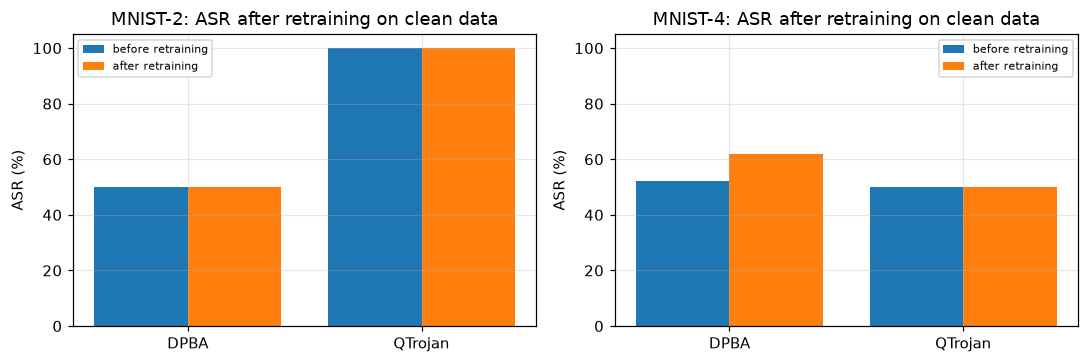

In [19]:
RT_ROWS = []
for task, d in DATA.items():
    k = d["K"]
    A_trig = trigger_inputs(d["A_te"])
    for seed in MODEL_SEEDS:
        gen = np.random.default_rng(3000 * seed + 41)
        # DPBA victim retrains
        p_new, _ = train(DPBA_MODELS[(task, seed)], d["A_rt"], d["y_rt"], k, RETRAIN_STEPS, RETRAIN_LR, gen, tag=f"[{task} seed {seed}] retrain DPBA", log_every=0)
        pr_t = predict(p_new, A_trig, k)
        DP = DPBA_ROWS[[i for i, r in enumerate(DPBA_ROWS) if r["task"] == task and r["seed"] == seed][0]]
        RT_ROWS.append(dict(task=task, seed=seed, attack="DPBA", CDA_before=DP["CDA_pct"], ASR_before=DP["ASR_pct"],
                            CDA_after=100 * accuracy(p_new, d["A_te"], d["y_te"], k), ASR_after=100 * float((pr_t == DPBA_TARGET).mean())))
        # QTrojan victim retrains (theta fixed beforehand)
        p_new, _ = train(MODELS[(task, seed)], d["A_rt"], d["y_rt"], k, RETRAIN_STEPS, RETRAIN_LR, gen, tag=f"[{task} seed {seed}] retrain QTrojan", log_every=0)
        probe, asr_after = d["A_te"][:N_ASR_PROBE], []
        for t in range(k):
            asr_after.append(100 * float((predict(p_new, probe, k, trojan_cfg(QT_THETA[(task, t)])) == t).mean()))
        before = df_qt[(df_qt.task == task) & (df_qt.seed == seed)].ASR_pct.mean()
        RT_ROWS.append(dict(task=task, seed=seed, attack="QTrojan", CDA_before=100 * accuracy(MODELS[(task, seed)], d["A_te"], d["y_te"], k), ASR_before=before,
                            CDA_after=100 * accuracy(p_new, d["A_te"], d["y_te"], k), ASR_after=float(np.mean(asr_after))))
        print(f"[{task} seed {seed}] retrained", flush=True)
df_rt = pd.DataFrame(RT_ROWS)
print("Retraining on new clean data (mean over seeds; QTrojan ASR = mean over the target classes):")
print(df_rt.groupby(["task", "attack"])[["CDA_before", "CDA_after", "ASR_before", "ASR_after"]].mean().round(1).to_string())

fig, axes = plt.subplots(1, len(DATA), figsize=(10, 3.4))
for ax, task in zip(np.atleast_1d(axes), DATA):
    s = df_rt[df_rt.task == task].groupby("attack")[["ASR_before", "ASR_after"]].mean()
    x = np.arange(len(s))
    ax.bar(x - 0.2, s.ASR_before, 0.4, label="before retraining"); ax.bar(x + 0.2, s.ASR_after, 0.4, label="after retraining")
    ax.set_xticks(x); ax.set_xticklabels(s.index); ax.set_ylim(0, 105); ax.set_ylabel("ASR (%)"); ax.set_title(f"{task}: ASR after retraining on clean data"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 10. Cost of the backdoored encoding layer (paper Section 3.4 / Figure 6)

The paper compiles the plain encoding layer and the backdoored one into pulse schedules and finds the same duration (320 dt). Qiskit 2.x no longer contains Qiskit Pulse, so we check the **gate-level equivalent**: a single-qubit gate sequence is compiled to the native set `rz` (a free virtual phase change) and `sx` (one physical pi/2 pulse). The number of physical pulses (`sx`, `x`) of `S-bar + S_x + S-tilde` is compared with that of `S_x` alone for random data and random `theta`. The pulse amplitudes and the exact duration of Figure 6 cannot be reproduced.

In [20]:
from qiskit import transpile
gen_g = np.random.default_rng(SEED)
rows = []
for _ in range(100):
    x, th = gen_g.uniform(0, np.pi, 2)
    plain = QuantumCircuit(1); plain.ry(float(x), 0)
    bd = QuantumCircuit(1); bd.rx(np.pi / 2, 0); bd.ry(float(x), 0); bd.rx(3 * np.pi / 2, 0); bd.ry(float(th), 0)
    dorm = QuantumCircuit(1); dorm.rx(0.0, 0); dorm.ry(float(x), 0); dorm.rx(0.0, 0); dorm.ry(0.0, 0)
    for name, c in [("plain S_x", plain), ("backdoored, triggered", bd), ("backdoored, benign file", dorm)]:
        t = transpile(c, basis_gates=["rz", "sx", "x"], optimization_level=3, seed_transpiler=SEED)
        ops = t.count_ops()
        rows.append(dict(layer=name, physical_pulses=ops.get("sx", 0) + ops.get("x", 0), rz_virtual=ops.get("rz", 0), depth=t.depth()))
df_ovh = pd.DataFrame(rows)
print(df_ovh.groupby("layer").agg(max_physical_pulses=("physical_pulses", "max"), mean_physical_pulses=("physical_pulses", "mean"),
                                   max_depth=("depth", "max")).round(2).to_string())
GATE_OVERHEAD_OK = df_ovh[df_ovh.layer != "plain S_x"].physical_pulses.max() <= df_ovh[df_ovh.layer == "plain S_x"].physical_pulses.max()
print("backdoored layer needs no more physical pulses than the plain encoding layer:", GATE_OVERHEAD_OK)

                         max_physical_pulses  mean_physical_pulses  max_depth
layer                                                                        
backdoored, benign file                    2                   2.0          4
backdoored, triggered                      2                   2.0          4
plain S_x                                  2                   2.0          4
backdoored layer needs no more physical pulses than the plain encoding layer: True


## 11. Dense angle encoding and the QLSTM claim (paper Figure 7)

Figure 7 shows a 4-qubit QLSTM with **dense** angle encoding (Eq. 2: two features per qubit, `cos(pi x1)|0> + e^(2 pi i x2) sin(pi x1)|1>`) whose prediction becomes a flat line "through two RX gates and one RY gate on each qubit". The QLSTM itself (cell wiring, sequence length, data, training) is not specified well enough to rebuild, so Figure 7 cannot be reproduced. What can be tested exactly is the single-qubit statement behind it: does the same `RX1 | encoding | RX2, RY` sandwich erase a *dense*-encoded input? Dense encoding is `RY(2 pi x1)` followed by a phase `RZ(2 pi x2)`. The `-y` pole is invariant under `RY` but not under `RZ`.

In [21]:
gen_d = np.random.default_rng(3)
def dense_state(x1, x2, mode, theta=1.0):
    c = QuantumCircuit(1)
    if mode in ("pre", "full"): c.rx(np.pi / 2, 0)
    c.ry(2 * np.pi * x1, 0); c.rz(2 * np.pi * x2, 0)            # Eq. 2 up to a global phase
    if mode == "full": c.rx(3 * np.pi / 2, 0); c.ry(theta, 0)
    return c
# the encoding equals Eq. 2 up to a global phase
x1, x2 = 0.3, 0.6
eq2 = Statevector([np.cos(np.pi * x1), np.exp(2j * np.pi * x2) * np.sin(np.pi * x1)])
assert Statevector(dense_state(x1, x2, "none")).equiv(eq2)
rows = []
for mode, label in [("none", "dense encoding only"), ("pre", "RX1(pi/2) + encoding"), ("full", "RX1 + encoding + RX2(3pi/2) + RY(theta)  (QTrojan)")]:
    s_x1 = np.array([bloch(dense_state(a, 0.37, mode)) for a in np.linspace(0, 1, 25)])     # vary x1, fix x2
    s_x2 = np.array([bloch(dense_state(0.21, b, mode)) for b in np.linspace(0, 1, 25)])     # vary x2, fix x1
    rows.append(dict(circuit=label, spread_when_x1_varies=float(np.abs(s_x1 - s_x1[0]).max()), spread_when_x2_varies=float(np.abs(s_x2 - s_x2[0]).max())))
df_dense = pd.DataFrame(rows)
print(df_dense.round(3).to_string(index=False))
DENSE_ERASED = bool(df_dense.iloc[2][["spread_when_x1_varies", "spread_when_x2_varies"]].max() < 1e-6)
print("QTrojan layers erase both dense-encoded features:", DENSE_ERASED)

                                           circuit  spread_when_x1_varies  spread_when_x2_varies
                               dense encoding only                    2.0                  1.937
                              RX1(pi/2) + encoding                    0.0                  2.000
RX1 + encoding + RX2(3pi/2) + RY(theta)  (QTrojan)                    0.0                  1.840
QTrojan layers erase both dense-encoded features: False


## 12. Side by side with the paper

Verdict rule: a number is **reproduced** if it is within 2 percentage points of the paper's value, otherwise **exceeded** (ours is higher) or **not reached** (ours is lower), with the gap. Qualitative claims are given a stated threshold. Numbers of this notebook are mean over the model seeds. Reading guide: the paper's attack numbers are 0 or 100 percent for the fixed-state attack by construction, so the interesting rows are the clean accuracy, the DPBA baseline, the partial attack and the retraining behaviour.

**Caveat for this committed run:** one model seed, very short training (`FAST_MODE = True`) and 100 test images, so one image is one percentage point and the seed-to-seed spread is not measured. The 4-class clean accuracy and the DPBA numbers in particular are budget-limited, not converged.

In [22]:
PAPER = {
    "clean": {"MNIST-2": 98.25, "MNIST-4": 58.6},
    "dpba_cda": {"MNIST-2": 91.56, "MNIST-4": 43.0}, "dpba_asr": {"MNIST-2": 99.5, "MNIST-4": 68.75},
    "qt_cda": {"MNIST-2": 98.25, "MNIST-4": 58.6}, "qt_asr": {"MNIST-2": 100.0, "MNIST-4": 100.0},
    "partial": {"MNIST-2": [100, 100, 100, 100], "MNIST-4": [61.18, 72.92, 81.4, 100]},
}
def verdict(ours, paper, tol=2.0):
    dlt = ours - paper
    return "reproduced" if abs(dlt) <= tol else (f"exceeded (+{dlt:.1f})" if dlt > 0 else f"not reached ({dlt:.1f})")
def mean_over_seeds(df, col, **flt):
    sub = df
    for k_, v_ in flt.items(): sub = sub[sub[k_] == v_]
    return float(sub[col].mean())

rows = []
OURS = {}
for task in DATA:
    OURS[("clean", task)] = mean_over_seeds(df_clean, "clean_test_acc_pct", task=task)
    OURS[("dpba_cda", task)] = mean_over_seeds(df_dpba, "CDA_pct", task=task)
    OURS[("dpba_asr", task)] = mean_over_seeds(df_dpba, "ASR_pct", task=task)
    OURS[("qt_cda", task)] = mean_over_seeds(df_qt, "CDA_dormant", task=task)
    OURS[("qt_asr", task)] = mean_over_seeds(df_qt, "ASR_pct", task=task)
    for key, label in [("clean", "clean QNN accuracy"), ("dpba_cda", "DPBA clean data accuracy"), ("dpba_asr", "DPBA attack success rate"),
                       ("qt_cda", "QTrojan CDA (dormant layers)"), ("qt_asr", "QTrojan ASR (mean over targets, prototype attacker)")]:
        rows.append(dict(claim=f"{task}: {label}", paper=PAPER[key][task], notebook=round(OURS[(key, task)], 2), verdict=verdict(OURS[(key, task)], PAPER[key][task])))
    first_t = df_part[(df_part.task == task) & (df_part.subset == "first m")]
    for m, pv in zip(PARTIAL_M, PAPER["partial"][task]):
        ov = float(first_t[first_t.m == m].ASR_best_target_pct.mean())
        rows.append(dict(claim=f"{task}: partial QTrojan, {m} qubit(s), ASR best target", paper=pv, notebook=round(ov, 2), verdict=verdict(ov, pv)))
# exact identity of the dormant backdoor
rows.append(dict(claim="QTrojan CDA identical to clean QNN (all predictions equal)", paper="identical", notebook=f"identical: {bool(df_qt.same_predictions.all())}",
                 verdict="reproduced" if bool(df_qt.same_predictions.all()) else "not reached"))
# relative improvements over DPBA, averaged over the two tasks
def rel(a, b): return 100 * (a / b - 1)
imp_cda = np.mean([rel(OURS[("qt_cda", t)], OURS[("dpba_cda", t)]) for t in DATA]); imp_asr = np.mean([rel(OURS[("qt_asr", t)], OURS[("dpba_asr", t)]) for t in DATA])
pap_cda = np.mean([rel(PAPER["qt_cda"][t], PAPER["dpba_cda"][t]) for t in DATA]); pap_asr = np.mean([rel(PAPER["qt_asr"][t], PAPER["dpba_asr"][t]) for t in DATA])
rows.append(dict(claim="QTrojan improves CDA over DPBA (relative %, mean of 2 tasks)", paper=f"21 (Table 2 gives {pap_cda:.1f})", notebook=round(imp_cda, 2), verdict=verdict(imp_cda, 21.0)))
rows.append(dict(claim="QTrojan improves ASR over DPBA (relative %, mean of 2 tasks)", paper=f"19.9 (Table 2 gives {pap_asr:.1f})", notebook=round(imp_asr, 2), verdict=verdict(imp_asr, 19.9)))
# qualitative claims with explicit thresholds
both = [(OURS[("dpba_cda", t)] >= OURS[("clean", t)] - 2.0) and (OURS[("dpba_asr", t)] >= 95.0) for t in DATA]
rows.append(dict(claim="DPBA cannot reach high CDA (within 2 points of clean) and high ASR (>= 95 %) together on the QNN", paper="claimed (Table 2)",
                 notebook=f"DPBA reaches both on: {[t for t, b in zip(DATA, both) if b]}", verdict="reproduced" if not any(both) else "not reproduced on at least one task"))
dr = df_rt[df_rt.attack == "DPBA"]; qr = df_rt[df_rt.attack == "QTrojan"]
drop = float((dr.ASR_before - dr.ASR_after).mean()); keep = float(qr.ASR_after.mean())
rows.append(dict(claim="clean retraining greatly reduces the ASR of DPBA (threshold: drop >= 10 points)", paper="claimed (Section 5)", notebook=f"ASR drop {drop:.1f} points",
                 verdict="reproduced" if drop >= 10 else "not reached"))
rows.append(dict(claim="QTrojan still works after clean retraining (threshold: mean ASR >= 90 %)", paper="claimed (Section 2.4, Table 1)", notebook=f"ASR after retraining {keep:.1f} %",
                 verdict="reproduced" if keep >= 90 else f"not reached ({keep:.1f} %)"))
rows.append(dict(claim="backdoored encoding layer adds no pulse duration (gate level: physical pulses)", paper="320 dt = 320 dt (Figure 6)", notebook=f"no extra pulses: {GATE_OVERHEAD_OK}",
                 verdict=("reproduced at gate level (pulses not checkable)" if GATE_OVERHEAD_OK else "not reproduced at gate level")))
rows.append(dict(claim="QTrojan flattens a QLSTM with dense encoding (Figure 7)", paper="figure", notebook=f"QLSTM not rebuilt; single dense-encoded qubit fully erased: {DENSE_ERASED}",
                 verdict="cannot be checked"))
df_cmp = pd.DataFrame(rows)
pd.set_option("display.width", 250, "display.max_colwidth", 90)
print(df_cmp.to_string(index=False))
print("\nverdict counts:", df_cmp.verdict.str.split(" ").str[0].value_counts().to_dict())

                                                                                           claim                          paper                                                          notebook                                         verdict
                                                                     MNIST-2: clean QNN accuracy                          98.25                                                              99.0                                      reproduced
                                                               MNIST-2: DPBA clean data accuracy                          91.56                                                             100.0                                 exceeded (+8.4)
                                                               MNIST-2: DPBA attack success rate                           99.5                                                              50.0                             not reached (-49.5)
                                

## 13. Reading the paper critically

* **The attack is a constant classifier.** With the triggered file every input gives the same output, so the ASR is 0 % or 100 % and "100 % ASR" is a property of the construction, not a measurement of an attack that had to fight the model. The ASR is also counted over all images, target-class images included, which is the definition that gives the baseline DPBA its high-looking numbers on easy tasks.
* **How is `theta` chosen?** The paper says the angle is "predefined by the attacker" but the attacker is supposed to know neither the data nor the training. We showed three attackers: a prototype attacker needs a few examples of the target class and the pre-processing pipeline; a data-free attacker with random angles hits each class only with a probability set by the model; a white-box attacker succeeds trivially. The headline 100 % is only reachable with some knowledge.
* **"CDA exactly the same" is a tautology.** The dormant layers are rotations by zero; their only effect is numerical noise. The relevant question is detection, not accuracy.
* **The DPBA comparison is soft.** Poisoning rate, trigger position, trigger value, training length and whether the baseline was trained with the same budget are not given, and the improvement figures (21 % and 19.9 %) cannot be recomputed from Table 2 alone (the table gives about 21.8 % and 23.0 % relative). The claim that a QNN cannot learn both tasks depends on those unpublished choices; with our choices the outcome is printed in the comparison table.
* **Noise.** The paper simulates FakeAlmaden noise; ours is exact and noiseless. Noise lowers the clean accuracy of both models but does not change the logic of the fixed-state attack.
* **Trust model.** The attack needs a trusted compiler to read a poisoned configuration file. Anyone who can write the calibration data can also change the calibration of the real gates, so "stealth" is relative; a cheap defence is also obvious from this notebook: run a few random inputs through the deployed circuit and check that the outputs are not all identical, or diff the configuration file against the vendor's.
* **Not reproduced.** Figure 6 (pulse schedules) and Figure 7 (QLSTM) need components that are not available or not specified; their status is "cannot be checked", with the gate-level and single-qubit surrogates reported above.

## 14. Exercises

1. **Random inputs test.** Write a detector that sends 10 random angle vectors through a deployed circuit and flags it when all outputs are identical. Does it catch the full QTrojan? Does it catch a partial QTrojan on 4 qubits?
2. **Better attacker.** Replace the class-mean `theta` by the training image of the target class that the *clean* model classifies with the highest confidence. Does the ASR after clean retraining (section 9) go up?
3. **Which qubits?** Repeat the partial QTrojan of section 7 pinning the m qubits that are *furthest* from the read-out qubits in the CRX ring. How does the ASR for m = 1 to 4 change, and why?
4. **Noise.** Add depolarising noise after every `CRX` gate (use `qml.DepolarizingChannel` on `default.mixed` with 6 qubits and a reduced circuit) and see whether the fixed-state attack still sends everything to one class.
5. **Dense encoding.** Using section 11, design a pre-encoding layer that also pins the phase feature `x2` of a dense-encoded qubit (hint: the layers must act after the `RZ`), and check it with the single-qubit test.

In [23]:
print(f"Total wall-clock of this notebook run: {(time.time() - T_START) / 60:.1f} min  (FAST_MODE = {FAST_MODE})")

Total wall-clock of this notebook run: 14.0 min  (FAST_MODE = True)
